# Clasificación y detección de opacidades compatibles con neumonía en radiografías de tórax

**Integrantes:** David Alberto Chaparro Gil (2221939) · Jose David Erazo Soraca (2230076) · Michael Alexander Ortiz Lozada (2191316)

**Dataset:** [RSNA Pneumonia Processed Dataset](https://www.kaggle.com/datasets/iamtapendu/rsna-pneumonia-processed-dataset) (derivado del RSNA Pneumonia Detection Challenge 2018 [1]).

**Objetivos**
1. **Clasificación:** imagen → `Target` (1 = opacidad pulmonar anotada, compatible con posible neumonía; 0 = sin opacidad anotada) con una CNN y *transfer learning*.
2. **Detección:** imagen → cajas delimitadoras (`x, y, width, height`) de las opacidades anotadas.


## 0. Configuración



In [ ]:
import os, sys, json, gc, random, hashlib
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    !pip install -q kagglehub torchmetrics pycocotools

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import torch
import torch.nn as nn
import torchvision
import torchmetrics
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from IPython.display import display, Markdown

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_WORKERS = 0 if os.name == "nt" else 2

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

def colate_det(batch):
    return tuple(zip(*batch))

def make_loader(ds, batch_size, shuffle=False, detection=False):
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=NUM_WORKERS,
                      pin_memory=DEVICE.type == "cuda", persistent_workers=NUM_WORKERS > 0,
                      worker_init_fn=seed_worker, generator=torch.Generator().manual_seed(SEED),
                      collate_fn=colate_det if detection else None)


GUARDAR_EN_DRIVE = True
EJECUCION = "v3"
REENTRENAR = False

if EN_COLAB and GUARDAR_EN_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/proyecto_neumonia") / EJECUCION
else:
    ROOT = (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()) / EJECUCION
RES_DIR, MODEL_DIR = ROOT / "resultados", ROOT / "models"
RES_DIR.mkdir(parents=True, exist_ok=True); MODEL_DIR.mkdir(parents=True, exist_ok=True)
if REENTRENAR:
    for f in MODEL_DIR.glob("*.pt"):
        f.unlink()
print("Modelos y resultados en:", ROOT, "| modelos guardados:", sorted(f.name for f in MODEL_DIR.glob("*.pt")))

def guardar_ck(obj, ruta):

    tmp = ruta.with_suffix(".tmp"); torch.save(obj, tmp); os.replace(tmp, ruta)
def cargar(ruta):
    return torch.load(ruta, map_location=DEVICE, weights_only=True)
def config_simple():
    return json.loads(json.dumps(config, default=str))
metricas, config = {}, {"seed": SEED}
def guardar_fig(nombre):
    plt.savefig(RES_DIR / f"{nombre}.png", dpi=150, bbox_inches="tight")

config["versiones"] = {"python": sys.version.split()[0], "torch": torch.__version__,
                       "torchvision": torchvision.__version__, "torchmetrics": torchmetrics.__version__}
print("Dispositivo:", DEVICE, "|", config["versiones"])

Mounted at /content/drive
Modelos y resultados en: /content/drive/MyDrive/proyecto_neumonia/v3 | modelos guardados: ['clasificador_resnet50.pt', 'clasificador_ultimo.pt', 'detector_fasterrcnn.pt', 'detector_fasterrcnn_v2.pt', 'detector_ultimo.pt', 'detector_v2_ultimo.pt']
Dispositivo: cuda | {'python': '3.13.16', 'torch': '2.14.1+cu130', 'torchvision': '0.29.1+cu130', 'torchmetrics': '1.9.0'}


- Importamos las librerías y fijamos la semilla en 42 para poder repetir los resultados.
- Montamos Drive para guardar los modelos en cada época y retomar si Colab se desconecta.

## 1. Datos

In [ ]:
import kagglehub
DATA_DIR = Path(kagglehub.dataset_download("iamtapendu/rsna-pneumonia-processed-dataset"))
config["dataset"] = "iamtapendu/rsna-pneumonia-processed-dataset"
print(DATA_DIR)

for root, dirs, files in os.walk(DATA_DIR):
    nivel = root.replace(str(DATA_DIR), "").count(os.sep)
    print("  " * nivel + os.path.basename(root) + "/", f"({len(files)} archivos)")
    for f in files[:3]:
        print("  " * (nivel + 1) + f)

100%|██████████| 10.9G/10.9G [02:19<00:00, 84.1MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/iamtapendu/rsna-pneumonia-processed-dataset/versions/1
1/ (2 archivos)
  stage2_test_metadata.csv
  stage2_train_metadata.csv
  Training/ (0 archivos)
    Masks/ (26684 archivos)
      e16597e4-4bad-4d6b-819a-3f94dac2454d.png
      8522f781-3c10-41c5-860b-dcdfb6746bbd.png
      e7f41761-1491-46b3-b718-a09637f90682.png
    Images/ (26684 archivos)
      e16597e4-4bad-4d6b-819a-3f94dac2454d.png
      8522f781-3c10-41c5-860b-dcdfb6746bbd.png
      e7f41761-1491-46b3-b718-a09637f90682.png
  Test/ (3000 archivos)
    219e8604-5624-4059-92c2-401e528484e2.png
    301fa177-ac7e-4d1e-88f7-b6e51d54cfe8.png
    1e9ab6d7-8cf5-48dc-a30b-afcccfc339e2.png


- Descargamos el dataset de Kaggle y revisamos cómo vienen las carpetas.
- Training trae Images y Masks con los mismos nombres; solo usamos Images.

In [ ]:
df = pd.read_csv(DATA_DIR / "stage2_train_metadata.csv")



IMG_DIR = DATA_DIR / "Training" / "Images"
img_paths = {p.stem: p for p in IMG_DIR.glob("*.png")}

filas_antes, ids_antes = len(df), df["patientId"].nunique()
df = df[df["patientId"].isin(img_paths)].reset_index(drop=True)
print(f"Radiografías en Training/Images: {len(img_paths)}")
print(f"Filas del CSV: {filas_antes} -> {len(df)} tras quitar IDs sin imagen ({filas_antes - len(df)} excluidas)")
print(f"IDs únicos: {ids_antes} -> {df['patientId'].nunique()}")
df.head()

Radiografías en Training/Images: 26684
Filas del CSV: 30227 -> 30227 tras quitar IDs sin imagen (0 excluidas)
IDs únicos: 26684 -> 26684


,patientId,x,y,width,height,Target,class,age,sex,modality,position
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,NaN,NaN,NaN,NaN,0,No Lung Opacity / Not Normal,51,F,CR,PA
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,NaN,NaN,NaN,NaN,0,No Lung Opacity / Not Normal,48,F,CR,PA
2,00322d4d-1c29-4943-afc9-b6754be640eb,NaN,NaN,NaN,NaN,0,No Lung Opacity / Not Normal,19,M,CR,AP
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,NaN,NaN,NaN,NaN,0,Normal,28,M,CR,PA
4,00436515-870c-4b36-a041-de91049b9ab4,264.0,152.0,213.0,379.0,1,Lung Opacity,32,F,CR,AP


- Cargamos el CSV de anotaciones y dejamos solo los IDs que tienen imagen.
- Cada fila es una caja, por eso hay más filas (30,227) que imágenes (26,684).

## 2. Exploración y auditoría de datos (EDA)



In [ ]:

print("Nulos por columna:")
print(df.isna().sum()[lambda s: s > 0])

contrad_target = (df.groupby("patientId")["Target"].nunique() > 1).sum()
contrad_clase = (df.groupby("patientId")["class"].nunique() > 1).sum()
print(f"IDs con Target contradictorio: {contrad_target} | con clase contradictoria: {contrad_clase}")

pos = df[df["Target"] == 1]
print("Positivos sin caja:", pos[["x", "y", "width", "height"]].isna().any(axis=1).sum())
print("Negativos con caja:", df[df["Target"] == 0][["x", "y", "width", "height"]].notna().any(axis=1).sum())
fuera = ((pos.x < 0) | (pos.y < 0) | (pos.width <= 0) | (pos.height <= 0) |
         (pos.x + pos.width > 1024) | (pos.y + pos.height > 1024)).sum()
print("Cajas fuera del rango 0-1024 o con tamaño <= 0:", fuera)
assert contrad_target == 0 and contrad_clase == 0, "Hay IDs con etiquetas contradictorias"

Nulos por columna:
x         20672
y         20672
width     20672
height    20672
dtype: int64
IDs con Target contradictorio: 0 | con clase contradictoria: 0
Positivos sin caja: 0
Negativos con caja: 0
Cajas fuera del rango 0-1024 o con tamaño <= 0: 0


- Revisamos nulos, etiquetas contradictorias y cajas fuera de la imagen; no hubo problemas.
- Los nulos de x, y, width y height son las imágenes sin opacidad, que no tienen caja.

Imágenes únicas: 26684
        imágenes  proporción
Target                      
0          20672       0.775
1           6012       0.225


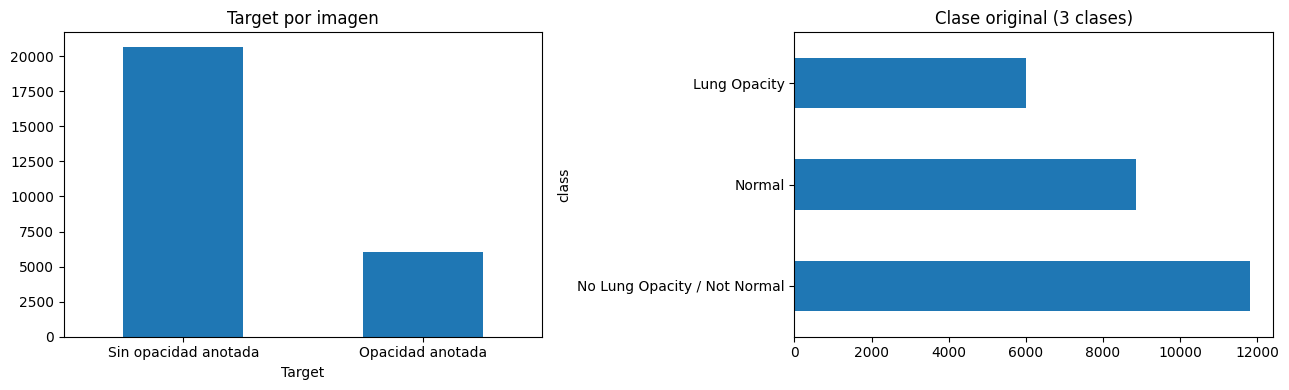

Cajas por imagen con opacidad:
1    2614
2    3266
3     119
4      13
Name: count, dtype: int64


In [ ]:
por_id = df.groupby("patientId")["Target"].max()
meta = df.drop_duplicates("patientId").set_index("patientId")
CLASE = meta["class"]

print("Imágenes únicas:", len(por_id))
print(por_id.value_counts().rename("imágenes").to_frame().assign(
    proporción=por_id.value_counts(normalize=True).round(3)))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
por_id.map({0: "Sin opacidad anotada", 1: "Opacidad anotada"}).value_counts().plot.bar(ax=ax[0], title="Target por imagen", rot=0)
CLASE.value_counts().plot.barh(ax=ax[1], title="Clase original (3 clases)")
plt.tight_layout(); guardar_fig("01_clases"); plt.show()

print("Cajas por imagen con opacidad:")
print(df[df["Target"] == 1].groupby("patientId").size().value_counts().sort_index())

- Contando por imagen: 77.5 % sin opacidad y 22.5 % con opacidad.
- Una imagen con opacidad tiene entre 1 y 4 cajas.

,imágenes,con_opacidad,% con opacidad,% del total
position,,,,
AP,12173,4664,38.3,45.6
PA,14511,1348,9.3,54.4


,imágenes,con_opacidad,% con opacidad,% del total
sex,,,,
F,11518,2502,21.7,43.2
M,15166,3510,23.1,56.8


count    26684.0
mean        47.0
std         16.8
min          1.0
25%         34.0
50%         49.0
75%         59.0
max        155.0
Name: age, dtype: float64
Edades > 100: 5 imágenes -> [148, 150, 151, 153, 155]


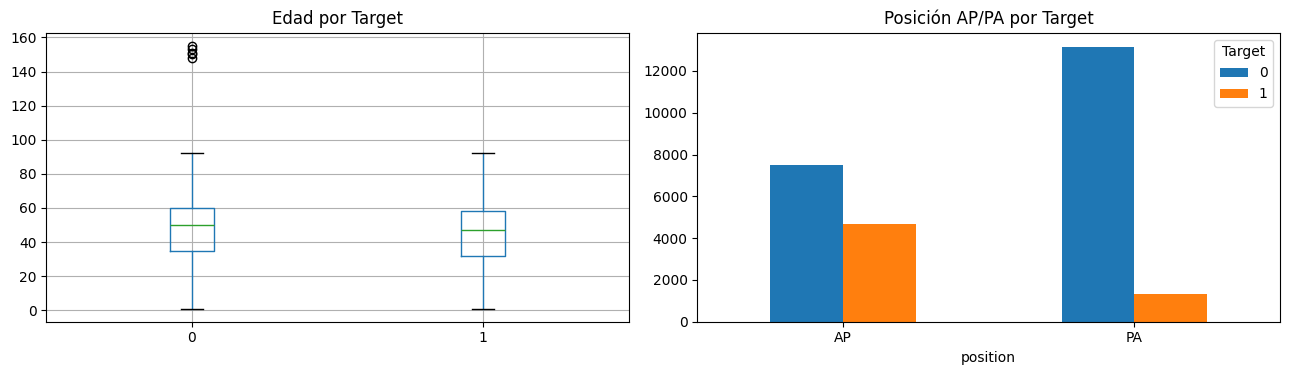

In [ ]:

for col in ["position", "sex"]:
    t = meta.groupby(col)["Target"].agg(imágenes="size", con_opacidad="sum")
    t["% con opacidad"] = (100 * t["con_opacidad"] / t["imágenes"]).round(1)
    t["% del total"] = (100 * t["imágenes"] / len(meta)).round(1)
    display(t)


print(meta["age"].describe().round(1))
raras = meta[meta["age"] > 100]
print(f"Edades > 100: {len(raras)} imágenes ->", sorted(raras["age"].tolist()))
config["edades_mayores_100"] = len(raras)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
meta.boxplot(column="age", by="Target", ax=ax[0]); ax[0].set_title("Edad por Target"); ax[0].set_xlabel("")
meta.groupby(["position", "Target"]).size().unstack().plot.bar(ax=ax[1], title="Posición AP/PA por Target", rot=0)
plt.suptitle(""); plt.tight_layout(); guardar_fig("02_subgrupos"); plt.show()

- Comparamos el % de opacidad por posición de la placa, sexo y edad.
- En placas AP hay 38.3 % con opacidad y en PA solo 9.3 %.
- Hay 5 edades por encima de 100 años; la edad no entra al modelo, así que se dejan.

In [ ]:

def hash_archivo(p):
    h = hashlib.md5()
    with open(p, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()

hashes = pd.Series({pid: hash_archivo(img_paths[pid]) for pid in tqdm(por_id.index, desc="Hash")})
dup = hashes[hashes.duplicated(keep=False)]
grupos_dup = [list(g.index) for _, g in dup.groupby(dup)]
print("Grupos de imágenes idénticas:", len(grupos_dup))
config["duplicados_exactos"] = len(grupos_dup)

Hash:   0%|          | 0/26684 [00:00<?, ?it/s]

Grupos de imágenes idénticas: 1


- Buscamos imágenes repetidas con un hash de cada archivo: solo hay un grupo.

In [ ]:

muestra = random.Random(SEED).sample(list(img_paths.values()), 300)
tamanos = set()
for p in muestra:
    with Image.open(p) as im:
        tamanos.add(im.size)
print("Tamaños encontrados en 300 imágenes:", tamanos)
assert len(tamanos) == 1, "Hay imágenes de distinto tamaño: habría que escalar las cajas por imagen"
IMG_W, IMG_H = tamanos.pop()
SX, SY = IMG_W / 1024, IMG_H / 1024
print(f"Factor de escala de cajas: x={SX}, y={SY}")

Tamaños encontrados en 300 imágenes: {(1024, 1024)}
Factor de escala de cajas: x=1.0, y=1.0


- Todas las imágenes son de 1024 x 1024, así que las cajas del CSV no se reescalan.

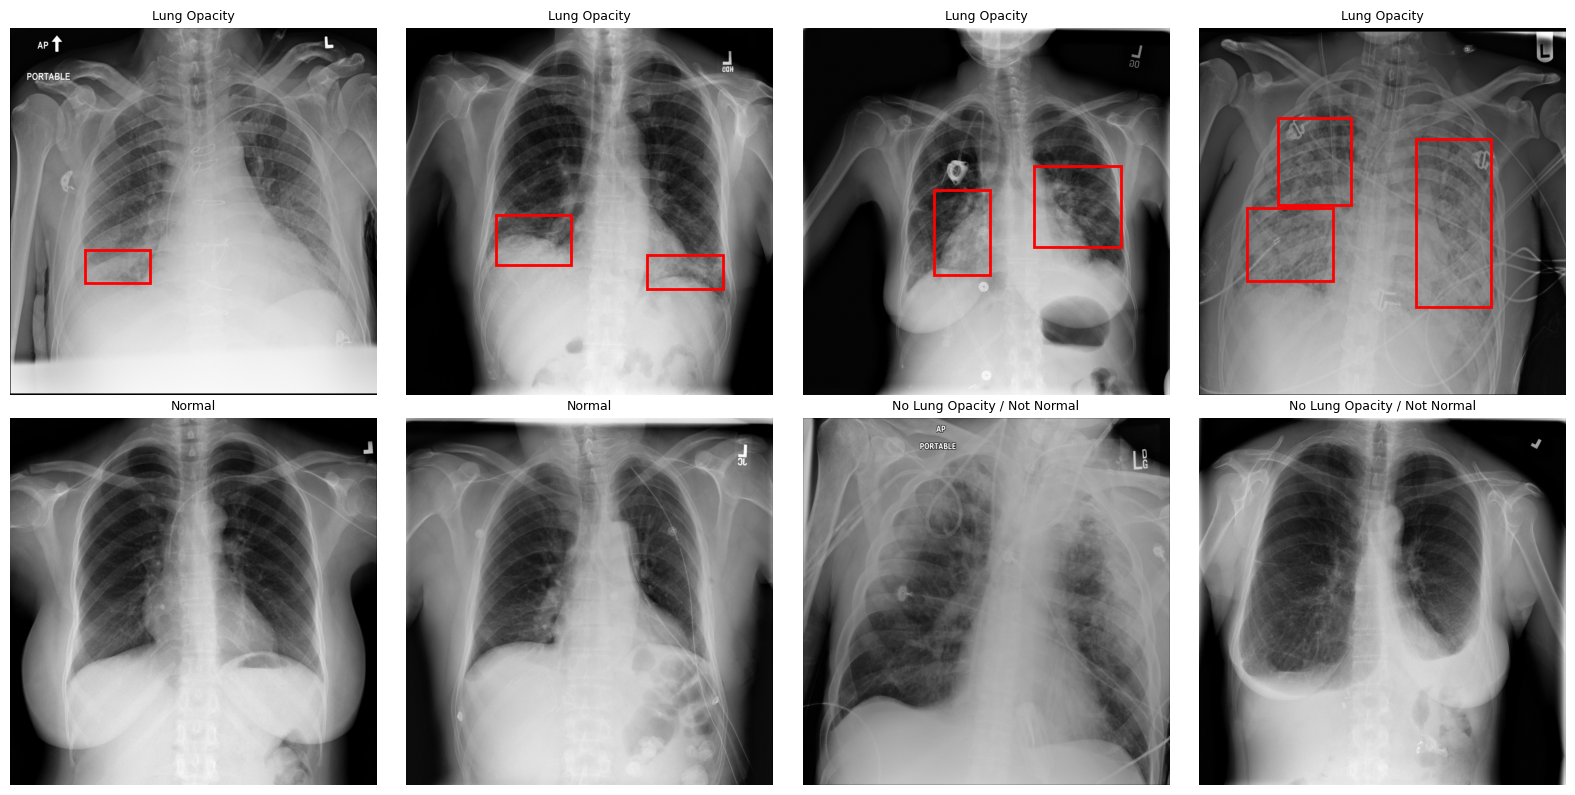

In [ ]:
CAJAS = {}
for r in df[df["Target"] == 1].itertuples():
    CAJAS.setdefault(r.patientId, []).append([r.x * SX, r.y * SY, (r.x + r.width) * SX, (r.y + r.height) * SY])

def mostrar(pid, ax, titulo=None):
    with Image.open(img_paths[pid]) as im:
        ax.imshow(im.convert("L"), cmap="gray")
    for x1, y1, x2, y2 in CAJAS.get(pid, []):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="red", linewidth=2))
    ax.set_title(titulo or CLASE[pid], fontsize=9); ax.axis("off")


n_cajas = pd.Series({k: len(v) for k, v in CAJAS.items()})
ejemplos = [pid for n, k in [(1, 1), (2, 2), (3, 1)] for pid in n_cajas[n_cajas == n].sample(k, random_state=SEED).index]
ejemplos += list(CLASE[CLASE == "Normal"].sample(2, random_state=SEED).index)
ejemplos += list(CLASE[CLASE == "No Lung Opacity / Not Normal"].sample(2, random_state=SEED).index)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for pid, ax in zip(ejemplos, axes.ravel()):
    mostrar(pid, ax)
plt.tight_layout(); guardar_fig("03_ejemplos"); plt.show()

- Guardamos las cajas de cada imagen y mostramos ejemplos de las tres clases (en rojo, la caja del radiólogo).

## 3. División de datos



In [ ]:
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

ids = por_id.rename("Target").reset_index()
ids["grupo"] = ids["patientId"].map(hashes)
assert ids["grupo"].notna().all()
assert not ids.groupby("grupo")["Target"].nunique().gt(1).any(), "Hay duplicados con etiquetas contradictorias"


partes = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
ids["parte"] = -1
for k_, (_, idx) in enumerate(partes.split(ids, ids["Target"], ids["grupo"])):
    ids.loc[idx, "parte"] = k_
train_ids = ids[ids["parte"] >= 6].copy()
val_ids = ids[ids["parte"].between(3, 5)].copy()
test_ids = ids[ids["parte"] <= 2].copy()

for a, b, n in [(train_ids, val_ids, "train/val"), (train_ids, test_ids, "train/test"), (val_ids, test_ids, "val/test")]:
    assert set(a["patientId"]).isdisjoint(b["patientId"]), f"IDs repetidos entre {n}"
    assert set(a["grupo"]).isdisjoint(b["grupo"]), f"Imágenes idénticas repartidas entre {n}"
print("OK: ni IDs ni imágenes idénticas compartidas entre train, val y test")
config["duplicados_entre_conjuntos"] = 0

for nombre, s in [("train", train_ids), ("val", val_ids), ("test", test_ids)]:
    print(f"{nombre}: {len(s)} imágenes ({100 * len(s) / len(ids):.1f} %) | % con opacidad = {s['Target'].mean():.3f}")
pd.concat([s.assign(conjunto=n) for n, s in [("train", train_ids), ("val", val_ids), ("test", test_ids)]]) \
  .to_csv(RES_DIR / "division_ids.csv", index=False)

OK: ni IDs ni imágenes idénticas compartidas entre train, val y test
train: 18677 imágenes (70.0 %) | % con opacidad = 0.226
val: 4003 imágenes (15.0 %) | % con opacidad = 0.223
test: 4004 imágenes (15.0 %) | % con opacidad = 0.223


- Dividimos por imagen en train, val y test (70/15/15), con el mismo % de opacidad en los tres.
- Las imágenes repetidas van al mismo conjunto para que no se cuelen en el test.

## 4. Clasificación (Target 0/1)



In [ ]:
IMG_SIZE = 224
BATCH = 32
EPOCHS_CLS = 10
RECALL_MIN = 0.80
config.update({"img_size_cls": IMG_SIZE, "batch_cls": BATCH, "epochs_cls": EPOCHS_CLS, "recall_min": RECALL_MIN})

norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
tf_train = transforms.Compose([
    transforms.Grayscale(3), transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ToTensor(), norm])
tf_eval = transforms.Compose([
    transforms.Grayscale(3), transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(), norm])

class ClasifDataset(Dataset):
    def __init__(self, tabla, tf):
        self.ids, self.y, self.tf = tabla["patientId"].values, tabla["Target"].values, tf
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        with Image.open(img_paths[self.ids[i]]) as im:
            img = im.convert("L")
        return self.tf(img), torch.tensor(self.y[i], dtype=torch.float32)

dl_train = make_loader(ClasifDataset(train_ids, tf_train), BATCH, shuffle=True)
dl_val = make_loader(ClasifDataset(val_ids, tf_eval), BATCH)
dl_test = make_loader(ClasifDataset(test_ids, tf_eval), BATCH)

- Las imágenes pasan a 224 x 224; en train se aplican giros y desplazamientos pequeños.
- Se normalizan con los valores de ImageNet porque el modelo viene preentrenado ahí.

In [ ]:
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_curve)

modelo = torchvision.models.resnet50(weights="IMAGENET1K_V2")
modelo.fc = nn.Linear(modelo.fc.in_features, 1)
modelo = modelo.to(DEVICE)
for prm in modelo.parameters():
    prm.requires_grad_(True)
pos_weight = torch.tensor([(train_ids["Target"] == 0).sum() / (train_ids["Target"] == 1).sum()], device=DEVICE)
criterio = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
LR_BACKBONE, LR_FC = 1e-5, 1e-4
optim = torch.optim.AdamW([
    {"params": [p for n, p in modelo.named_parameters() if not n.startswith("fc.")], "lr": LR_BACKBONE},
    {"params": modelo.fc.parameters(), "lr": LR_FC}], weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optim, mode="max", factor=0.5, patience=1)
config.update({"pos_weight": round(pos_weight.item(), 3), "lr_backbone": LR_BACKBONE, "lr_fc": LR_FC,
               "scheduler": "ReduceLROnPlateau(max, factor=0.5, patience=1) sobre AUC de validación"})

@torch.inference_mode()
def predecir(m, dl, crit):

    gc.collect(); m.eval(); probs, ys = [], []; suma, n = 0.0, 0
    for x, y in dl:
        x, yd = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        logits = m(x).squeeze(1)
        suma += crit(logits, yd).item() * len(y); n += len(y)
        probs.append(logits.sigmoid().cpu()); ys.append(y)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy(), suma / n

RUTA_CLS = MODEL_DIR / "clasificador_resnet50.pt"
RUTA_CLS_ULT = MODEL_DIR / "clasificador_ultimo.pt"
mejor_auc, mejor_ep_cls, historial, inicio = -float("inf"), None, [], 0
if RUTA_CLS_ULT.exists():
    ck = cargar(RUTA_CLS_ULT)
    modelo.load_state_dict(ck["modelo"]); optim.load_state_dict(ck["optim"]); scheduler.load_state_dict(ck["scheduler"])
    mejor_auc, mejor_ep_cls, historial, inicio = ck["mejor_auc"], ck["mejor_ep"], ck["historial"], ck["epoca"]
    del ck
    print(f"Retomando desde Drive: {inicio} de {EPOCHS_CLS} épocas ya entrenadas")
for ep in range(inicio, EPOCHS_CLS):
    gc.collect(); modelo.train(); perdida = 0
    lr_ep = optim.param_groups[0]["lr"]
    for x, y in tqdm(dl_train, desc=f"Época {ep + 1}/{EPOCHS_CLS}"):
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optim.zero_grad()
        loss = criterio(modelo(x).squeeze(1), y)
        loss.backward(); optim.step()
        perdida += loss.item() * len(x)
    p, y, loss_val = predecir(modelo, dl_val, criterio)
    auc_val = float(roc_auc_score(y, p))
    historial.append({"epoca": ep + 1, "lr_backbone": lr_ep, "loss_train": perdida / len(dl_train.dataset),
                      "loss_val": loss_val, "auc_val": auc_val, "ap_val": float(average_precision_score(y, p))})
    print({k: round(v, 6) if k == "lr_backbone" else round(v, 4) for k, v in historial[-1].items()})
    scheduler.step(auc_val)
    if auc_val > mejor_auc:
        mejor_auc, mejor_ep_cls = auc_val, ep + 1
        guardar_ck({"modelo": modelo.state_dict(), "epoca": ep + 1}, RUTA_CLS)
    guardar_ck({"modelo": modelo.state_dict(), "optim": optim.state_dict(), "scheduler": scheduler.state_dict(),
                "epoca": ep + 1, "historial": historial, "mejor_auc": mejor_auc, "mejor_ep": mejor_ep_cls,
                "config": config_simple()}, RUTA_CLS_ULT)
display(pd.DataFrame(historial).round(4))
print("Mejor época (AUC de validación):", mejor_ep_cls)
config["mejor_epoca_cls"] = mejor_ep_cls

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 160MB/s]


Retomando desde Drive: 10 de 10 épocas ya entrenadas


,epoca,lr_backbone,loss_train,loss_val,auc_val,ap_val
0,1,0.0,0.8421,0.7679,0.8365,0.6052
1,2,0.0,0.7423,0.7383,0.8506,0.6367
2,3,0.0,0.7062,0.7184,0.8584,0.6612
3,4,0.0,0.6811,0.7068,0.8654,0.6761
4,5,0.0,0.6652,0.7066,0.8670,0.6793
5,6,0.0,0.6480,0.6974,0.8681,0.6751
6,7,0.0,0.5992,0.7269,0.8642,0.6734
7,8,0.0,0.5407,0.7702,0.8636,0.6546
8,9,0.0,0.3748,0.9066,0.8565,0.6493
9,10,0.0,0.2404,1.1171,0.8499,0.6282


Mejor época (AUC de validación): 6


- ResNet-50 preentrenada en ImageNet con una sola salida: opacidad sí o no.
- Por el desbalance usamos pos_weight en la pérdida. La red aprende con lr 1e-5 y la capa nueva con 1e-4.
- Se entrenan 10 épocas y se guarda la de mejor AUC en validación

In [ ]:
import sys

modelo.load_state_dict(cargar(RUTA_CLS)["modelo"])   # siempre: otras celdas usan `modelo`

f_cache = RES_DIR / "pred_clasificador.npz"
firma = f"{RUTA_CLS.stat().st_mtime_ns}|{len(dl_val.dataset)}|{len(dl_test.dataset)}"

def predecir_rapido(m, dl, crit):
    # 2 procesos leyendo imágenes en paralelo; si falla el multiprocesamiento, vuelve a num_workers=0
    try:
        dl2 = DataLoader(dl.dataset, batch_size=dl.batch_size, shuffle=False, num_workers=2,
                         pin_memory=DEVICE.type == "cuda")
        return predecir(m, dl2, crit)
    except Exception as e:
        print("Los workers fallaron, se usa num_workers=0:", type(e).__name__)
        dl.num_workers = 0
        return predecir(m, dl, crit)

if f_cache.exists() and str(np.load(f_cache)["firma"]) == firma:
    d = np.load(f_cache)
    p_val, y_val, p_test, y_test = d["p_val"], d["y_val"], d["p_test"], d["y_test"]
    print("Predicciones cargadas del caché")
else:
    p_val, y_val, _ = predecir_rapido(modelo, dl_val, criterio)
    p_test, y_test, _ = predecir_rapido(modelo, dl_test, criterio)
    np.savez(f_cache, p_val=np.asarray(p_val), y_val=np.asarray(y_val),
             p_test=np.asarray(p_test), y_test=np.asarray(y_test), firma=firma)

prec, rec, thr = precision_recall_curve(y_val, p_val)
cumple = rec[:-1] >= RECALL_MIN
if cumple.any():
    UMBRAL = float(thr[np.argmax(np.where(cumple, prec[:-1], -1))])
else:
    f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
    UMBRAL = float(thr[np.argmax(f1s)])
config["umbral"] = UMBRAL
print(f"Umbral elegido en validación: {UMBRAL:.3f}")

def resumen(y, p, u):
    pred = (p >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"umbral": round(u, 3), "auc": roc_auc_score(y, p), "ap": average_precision_score(y, p),
            "recall": tp / (tp + fn), "especificidad": tn / (tn + fp),
            "precision": tp / (tp + fp) if tp + fp else 0.0, "f1": f1_score(y, pred),
            "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn)}


tabla = pd.DataFrame({"validación (umbral elegido)": resumen(y_val, p_val, UMBRAL),
                      "test (umbral elegido)": resumen(y_test, p_test, UMBRAL),
                      "test (umbral 0.5, referencia)": resumen(y_test, p_test, 0.5)}).T
display(tabla.round(3))
metricas["clasificacion"] = {k: float(v) for k, v in resumen(y_test, p_test, UMBRAL).items()}
metricas["clasificacion_umbral_0.5"] = {k: float(v) for k, v in resumen(y_test, p_test, 0.5).items()}

Predicciones cargadas del caché
Umbral elegido en validación: 0.508


,umbral,auc,ap,recall,especificidad,precision,f1,tp,fp,fn,tn
validación (umbral elegido),0.508,0.868,0.675,0.801,0.761,0.491,0.609,715.0,742.0,178.0,2368.0
test (umbral elegido),0.508,0.872,0.681,0.798,0.776,0.506,0.619,713.0,697.0,180.0,2414.0
"test (umbral 0.5, referencia)",0.500,0.872,0.681,0.804,0.769,0.500,0.617,718.0,718.0,175.0,2393.0


- El umbral se elige en validación: el de mayor precisión con recall de al menos 0.80 (quedó en 0.508).
- Con ese umbral se evalúa una sola vez en test: AUC 0.872 y recall 0.80.

,imágenes,marcadas,% marcadas como opacidad
clase,,,
Lung Opacity,893,713,79.8
No Lung Opacity / Not Normal,1756,674,38.4
Normal,1355,23,1.7


,% con opacidad,auc,ap,recall,especificidad,precision,tp,fp,fn,tn
AP,0.387,0.822,0.744,0.893,0.519,0.540,618.0,527.0,74.0,569.0
PA,0.091,0.830,0.368,0.473,0.916,0.358,95.0,170.0,106.0,1845.0


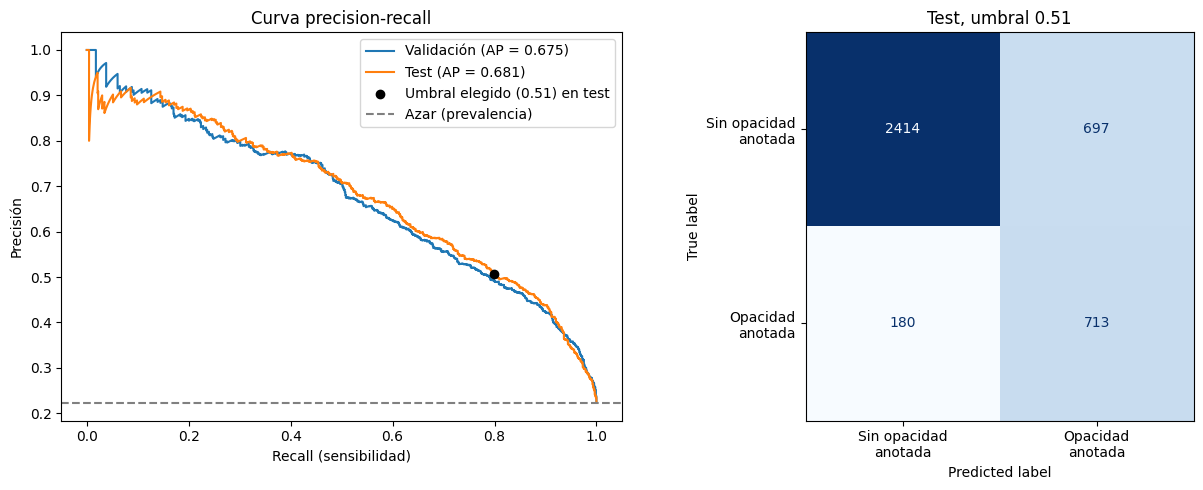

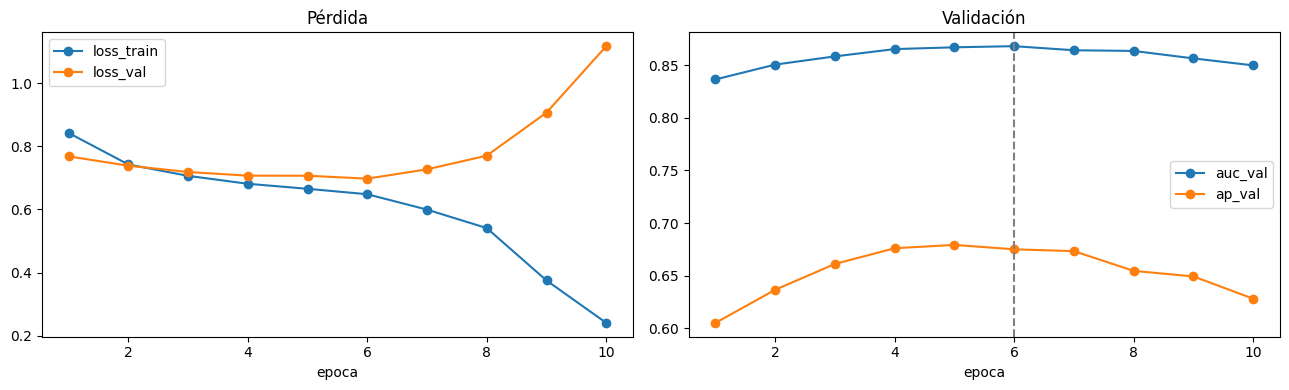

In [ ]:

pred_test = (p_test >= UMBRAL).astype(int)
por_clase = pd.DataFrame({"clase": CLASE[test_ids["patientId"]].values, "marcada_opacidad": pred_test})
por_clase = por_clase.groupby("clase")["marcada_opacidad"].agg(imágenes="size", marcadas="sum")
por_clase["% marcadas como opacidad"] = (100 * por_clase["marcadas"] / por_clase["imágenes"]).round(1)
display(por_clase)
metricas["clasificacion_por_clase"] = por_clase["% marcadas como opacidad"].to_dict()


POS = df.groupby("patientId")["position"].first()
posicion_test = POS[test_ids["patientId"]].values
por_pos = {p_: resumen(y_test[posicion_test == p_], p_test[posicion_test == p_], UMBRAL) for p_ in ["AP", "PA"]}
tabla_pos = pd.DataFrame(por_pos).T
tabla_pos.insert(0, "% con opacidad", [y_test[posicion_test == p_].mean() for p_ in ["AP", "PA"]])
display(tabla_pos[["% con opacidad", "auc", "ap", "recall", "especificidad", "precision", "tp", "fp", "fn", "tn"]].round(3))
metricas["clasificacion_por_posicion"] = {p_: {k: float(v) for k, v in r_.items()} for p_, r_ in por_pos.items()}

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for nombre, yy, pp in [("Validación", y_val, p_val), ("Test", y_test, p_test)]:
    pr, rc, _ = precision_recall_curve(yy, pp)
    ax[0].plot(rc, pr, label=f"{nombre} (AP = {average_precision_score(yy, pp):.3f})")
r = metricas["clasificacion"]
ax[0].scatter([r["recall"]], [r["precision"]], color="black", zorder=3, label=f"Umbral elegido ({UMBRAL:.2f}) en test")
ax[0].axhline(y_test.mean(), color="gray", ls="--", label="Azar (prevalencia)")
ax[0].set_xlabel("Recall (sensibilidad)"); ax[0].set_ylabel("Precisión"); ax[0].set_title("Curva precision-recall"); ax[0].legend()
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test),
                       display_labels=["Sin opacidad\nanotada", "Opacidad\nanotada"]).plot(ax=ax[1], cmap="Blues", colorbar=False)
ax[1].set_title(f"Test, umbral {UMBRAL:.2f}")
plt.tight_layout(); guardar_fig("04_clasificacion_pr_matriz"); plt.show()

h = pd.DataFrame(historial)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
h.plot(x="epoca", y=["loss_train", "loss_val"], ax=ax[0], marker="o", title="Pérdida")
h.plot(x="epoca", y=["auc_val", "ap_val"], ax=ax[1], marker="o", title="Validación")
ax[1].axvline(mejor_ep_cls, color="gray", ls="--")
plt.tight_layout(); guardar_fig("05_curvas_clasificacion"); plt.show()
h.to_csv(RES_DIR / "historial_clasificacion.csv", index=False)

- Casi todas las falsas alarmas son de la clase No Lung Opacity / Not Normal; las Normal casi no se marcan (1.7 %).
- Con el mismo umbral, en AP detecta más casos pero también da más falsas alarmas que en PA.
- En las curvas se ve que después de la época 6 la pérdida de validación sube: el modelo empieza a sobreajustar.

In [ ]:

del modelo, optim, scheduler, criterio, dl_train, dl_val, dl_test
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"Memoria GPU en uso: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

Memoria GPU en uso: 0.00 GB


- Liberamos la memoria de la GPU antes de pasar al detector.

## 5. Detección (cajas delimitadoras)



In [ ]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
import torchvision.transforms.functional as TF
from torchmetrics.detection import MeanAveragePrecision

EPOCHS_DET = 3
BATCH_DET = 8
DET_SIZE = min(IMG_W, 512)
SCORE_MIN = 0.5
IOU_MIN = 0.5
config.update({"epochs_det": EPOCHS_DET, "batch_det": BATCH_DET, "det_size": DET_SIZE,
               "score_min": SCORE_MIN, "iou_min": IOU_MIN})

class DetDataset(Dataset):
    def __init__(self, tabla, flip=False):
        self.ids, self.flip = tabla["patientId"].values, flip
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        pid = self.ids[i]
        with Image.open(img_paths[pid]) as im:
            img = TF.to_tensor(im.convert("RGB"))
        cajas = torch.tensor(CAJAS.get(pid, []), dtype=torch.float32).reshape(-1, 4)
        if self.flip and random.random() < 0.5:
            img = img.flip(-1)
            cajas[:, [0, 2]] = img.shape[-1] - cajas[:, [2, 0]]
        return img, {"boxes": cajas, "labels": torch.ones(len(cajas), dtype=torch.int64)}

pos_tr = train_ids[train_ids["Target"] == 1]
neg_tr = train_ids[train_ids["Target"] == 0].sample(len(pos_tr) // 2, random_state=SEED)
det_train_ids = pd.concat([pos_tr, neg_tr])
det_val_ids, _ = train_test_split(val_ids, train_size=1000, stratify=val_ids["Target"], random_state=SEED)

for nombre, s in [("train detección", det_train_ids), ("val detección", det_val_ids), ("test", test_ids)]:
    print(f"{nombre}: {len(s)} imágenes | con opacidad: {int(s['Target'].sum())} ({100 * s['Target'].mean():.1f} %)")
config["det_train"] = {"imagenes": len(det_train_ids), "positivas": int(det_train_ids["Target"].sum())}
config["det_val"] = {"imagenes": len(det_val_ids), "positivas": int(det_val_ids["Target"].sum())}
det_val_ids.to_csv(RES_DIR / "val_deteccion_ids.csv", index=False)

dl_det_train = make_loader(DetDataset(det_train_ids, flip=True), BATCH_DET, shuffle=True, detection=True)
dl_det_val = make_loader(DetDataset(det_val_ids), BATCH_DET, detection=True)
dl_det_test = make_loader(DetDataset(test_ids), BATCH_DET, detection=True)

det = fasterrcnn_resnet50_fpn_v2(weights="DEFAULT", min_size=DET_SIZE, max_size=DET_SIZE)
det.roi_heads.box_predictor = FastRCNNPredictor(det.roi_heads.box_predictor.cls_score.in_features, 2)
det = det.to(DEVICE)
optim_det = torch.optim.SGD(det.parameters(), lr=0.005, momentum=0.9, weight_decay=1e-4)

train detección: 6339 imágenes | con opacidad: 4226 (66.7 %)
val detección: 1000 imágenes | con opacidad: 223 (22.3 %)
test: 4004 imágenes | con opacidad: 893 (22.3 %)
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:01<00:00, 154MB/s]


- Faster R-CNN preentrenado en COCO; cambiamos la última capa a 2 clases (fondo y opacidad) y usamos imágenes de 512.
- Para entrenar tomamos todas las positivas de train y la mitad de esa cantidad de negativas, por tiempo en Colab.

Retomando desde Drive: 3 de 3 épocas ya entrenadas


,epoca,loss_classifier,loss_box_reg,loss_objectness,loss_rpn_box_reg,mAP@0.5,mAP
0,1,0.0890,0.1128,0.0166,0.0040,0.4153,0.1202
1,2,0.0770,0.1070,0.0105,0.0035,0.3883,0.1222
2,3,0.0699,0.1010,0.0080,0.0033,0.3934,0.1162


Mejor época (mAP@0.5 de validación): 1


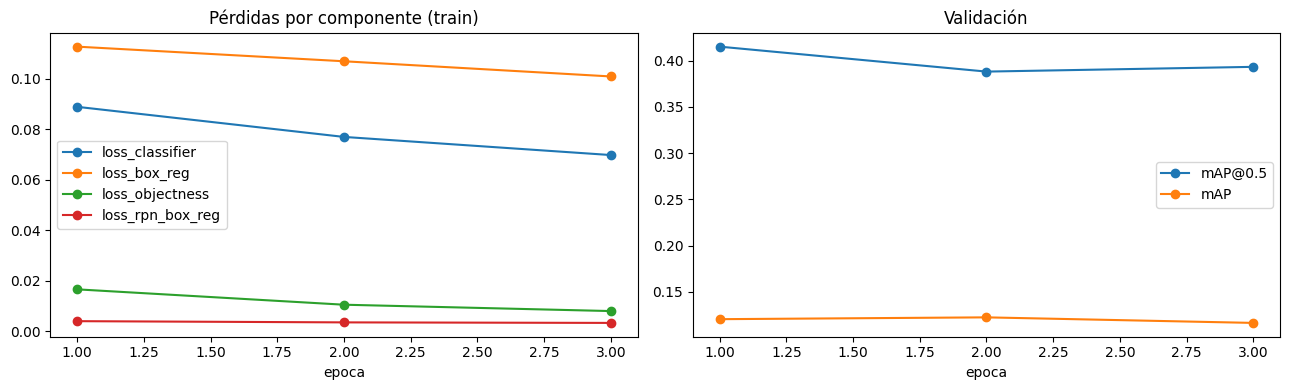

In [ ]:
@torch.no_grad()
def evaluar_det(m, dl):

    gc.collect(); m.eval(); metrica = MeanAveragePrecision(iou_type="bbox"); max_scores, preds = [], []
    for imgs, tgts in dl:
        salidas = [{k: v.cpu() for k, v in s.items()} for s in m([i.to(DEVICE) for i in imgs])]
        metrica.update(salidas, list(tgts))
        for s in salidas:
            max_scores.append(s["scores"].max().item() if len(s["scores"]) else 0.0)
            keep = s["scores"] >= SCORE_MIN
            preds.append((s["boxes"][keep], s["scores"][keep]))
    r = metrica.compute()
    return {"mAP@0.5": r["map_50"].item(), "mAP": r["map"].item()}, np.array(max_scores), preds

RUTA_DET = MODEL_DIR / "detector_fasterrcnn.pt"
RUTA_DET_ULT = MODEL_DIR / "detector_ultimo.pt"
mejor_map, mejor_ep_det, hist_det, inicio = -float("inf"), None, [], 0
if RUTA_DET_ULT.exists():
    ck = cargar(RUTA_DET_ULT)
    det.load_state_dict(ck["modelo"]); optim_det.load_state_dict(ck["optim"])
    mejor_map, mejor_ep_det, hist_det, inicio = ck["mejor_map"], ck["mejor_ep"], ck["historial"], ck["epoca"]
    del ck
    print(f"Retomando desde Drive: {inicio} de {EPOCHS_DET} épocas ya entrenadas")
for ep in range(inicio, EPOCHS_DET):
    gc.collect(); det.train(); suma = {}
    for imgs, tgts in tqdm(dl_det_train, desc=f"Época {ep + 1}/{EPOCHS_DET}"):
        imgs = [i.to(DEVICE) for i in imgs]
        tgts = [{k: v.to(DEVICE) for k, v in t.items()} for t in tgts]
        partes = det(imgs, tgts)
        loss = sum(partes.values())
        optim_det.zero_grad(); loss.backward(); optim_det.step()
        for k, v in partes.items():
            suma[k] = suma.get(k, 0) + v.item()
    r, _, _ = evaluar_det(det, dl_det_val)
    hist_det.append({"epoca": ep + 1, **{k: v / len(dl_det_train) for k, v in suma.items()}, **r})
    print({k: round(v, 4) for k, v in hist_det[-1].items()})
    if r["mAP@0.5"] > mejor_map:
        mejor_map, mejor_ep_det = r["mAP@0.5"], ep + 1
        guardar_ck({"modelo": det.state_dict(), "epoca": ep + 1}, RUTA_DET)
    guardar_ck({"modelo": det.state_dict(), "optim": optim_det.state_dict(), "epoca": ep + 1,
                "historial": hist_det, "mejor_map": mejor_map, "mejor_ep": mejor_ep_det,
                "config": config_simple()}, RUTA_DET_ULT)
display(pd.DataFrame(hist_det).round(4))
print("Mejor época (mAP@0.5 de validación):", mejor_ep_det)
config["mejor_epoca_det"] = mejor_ep_det

hd = pd.DataFrame(hist_det); hd.to_csv(RES_DIR / "historial_deteccion.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
hd.plot(x="epoca", y=["loss_classifier", "loss_box_reg", "loss_objectness", "loss_rpn_box_reg"], ax=ax[0], marker="o", title="Pérdidas por componente (train)")
hd.plot(x="epoca", y=["mAP@0.5", "mAP"], ax=ax[1], marker="o", title="Validación")
plt.tight_layout(); guardar_fig("06_curvas_deteccion"); plt.show()

- Se entrenan 3 épocas y se guarda la de mejor mAP@0.5 en validación (la 1).

In [ ]:
from torchvision.ops import box_iou

def emparejar(boxes, scores, gt):

    boxes = boxes[scores.argsort(descending=True)]
    usada = torch.zeros(len(gt), dtype=torch.bool); ious = []
    if len(boxes) and len(gt):
        for fila in box_iou(boxes, gt):
            libre = fila.clone(); libre[usada] = -1
            v, j = libre.max(0)
            if v.item() >= IOU_MIN:
                usada[j] = True; ious.append(v.item())
    tp = len(ious)
    return tp, len(boxes) - tp, len(gt) - tp, ious

def metricas_cajas(filtro=None):

    TP = FP = FN = 0; ious = []
    tp_img, n_pred, iou_max = np.zeros(len(pids_test), int), np.zeros(len(pids_test), int), np.zeros(len(pids_test))
    for i, (pid, (b, s)) in enumerate(zip(pids_test, preds_test)):
        if filtro is not None and not filtro[i]:
            b, s = b[:0], s[:0]
        gt = torch.tensor(CAJAS.get(pid, []), dtype=torch.float32).reshape(-1, 4)
        tp, fp, fn, iu = emparejar(b, s, gt)
        TP += tp; FP += fp; FN += fn; ious += iu
        tp_img[i], n_pred[i] = tp, len(b)
        if len(b) and len(gt):
            iou_max[i] = box_iou(b, gt).max().item()
    res = {"recall_cajas": TP / (TP + FN), "precision_cajas": TP / max(TP + FP, 1),
           "imagenes_con_opacidad_localizadas": float((tp_img[pos] > 0).mean()),
           "imagenes_sin_opacidad_con_caja": float((n_pred[neg] > 0).mean()),
           "iou_medio_emparejadas": float(np.mean(ious)) if ious else float("nan"),
           "tp": TP, "fp": FP, "fn": FN}
    return res, tp_img, n_pred, iou_max

det.load_state_dict(cargar(RUTA_DET)["modelo"])
r_test, max_test, preds_test = evaluar_det(det, dl_det_test)
y_det = test_ids["Target"].values
pids_test = test_ids["patientId"].values
pos, neg = y_det == 1, y_det == 0
pasa = p_test >= UMBRAL

solo, tp_img, n_pred, iou_max = metricas_cajas()
casc, _, _, _ = metricas_cajas(pasa)
localizada, tiene_caja = tp_img > 0, n_pred > 0

metricas["deteccion"] = {**r_test, **solo,
    "imagenes_con_opacidad_con_alguna_caja_sin_exigir_ubicacion": float(tiene_caja[pos].mean())}
metricas["cascada"] = {"solo_detector": solo, "clasificador+detector": casc}

NOMBRES = {"recall_cajas": f"Recall por caja (IoU ≥ {IOU_MIN})", "precision_cajas": f"Precisión por caja (IoU ≥ {IOU_MIN})",
           "imagenes_con_opacidad_localizadas": "Imágenes con opacidad con ≥ 1 caja bien ubicada",
           "imagenes_sin_opacidad_con_caja": "Imágenes sin opacidad con alguna caja (falsa alarma)",
           "iou_medio_emparejadas": "IoU medio de las parejas aceptadas", "tp": "TP (cajas)", "fp": "FP (cajas)", "fn": "FN (cajas)"}
print(f"mAP@0.5 = {r_test['mAP@0.5']:.3f} | mAP@[0.5:0.95] = {r_test['mAP']:.3f}")
display(pd.DataFrame({"Solo detector": solo, "Clasificador + detector": casc}).rename(index=NOMBRES).round(3))
print(f"De {pos.sum()} imágenes con opacidad: {localizada[pos].sum()} con caja bien ubicada, "
      f"{(tiene_caja & ~localizada)[pos].sum()} solo con cajas mal ubicadas y {(~tiene_caja)[pos].sum()} sin caja. "
      f"Sin exigir ubicación, {100 * tiene_caja[pos].mean():.1f} % recibe alguna caja.")


posicion_det = POS[pids_test].values
display(pd.DataFrame({p_: {"Imágenes con opacidad localizadas": localizada[pos & (posicion_det == p_)].mean(),
                           "Imágenes sin opacidad con caja": tiene_caja[neg & (posicion_det == p_)].mean()}
                      for p_ in ["AP", "PA"]}).round(3))

mAP@0.5 = 0.379 | mAP@[0.5:0.95] = 0.116


,Solo detector,Clasificador + detector
Recall por caja (IoU ≥ 0.5),0.665,0.606
Precisión por caja (IoU ≥ 0.5),0.226,0.267
Imágenes con opacidad con ≥ 1 caja bien ubicada,0.735,0.651
Imágenes sin opacidad con alguna caja (falsa alarma),0.389,0.207
IoU medio de las parejas aceptadas,0.668,0.669
TP (cajas),945.000,861.000
FP (cajas),3233.000,2367.000
FN (cajas),475.000,559.000


De 893 imágenes con opacidad: 656 con caja bien ubicada, 170 solo con cajas mal ubicadas y 67 sin caja. Sin exigir ubicación, 92.5 % recibe alguna caja.


,AP,PA
Imágenes con opacidad localizadas,0.796,0.522
Imágenes sin opacidad con caja,0.709,0.215


- En test se mide el mAP y además se empareja cada caja predicha con una anotada (cuenta si el IoU es de al menos 0.5).
- El detector ubica bien la opacidad en el 73.5 % de las imágenes que la tienen, pero pone cajas en el 38.9 % de las que no.
- Si primero filtramos con el clasificador, esas falsas alarmas bajan al 20.7 %, pero las bien ubicadas bajan al 65.1 %.

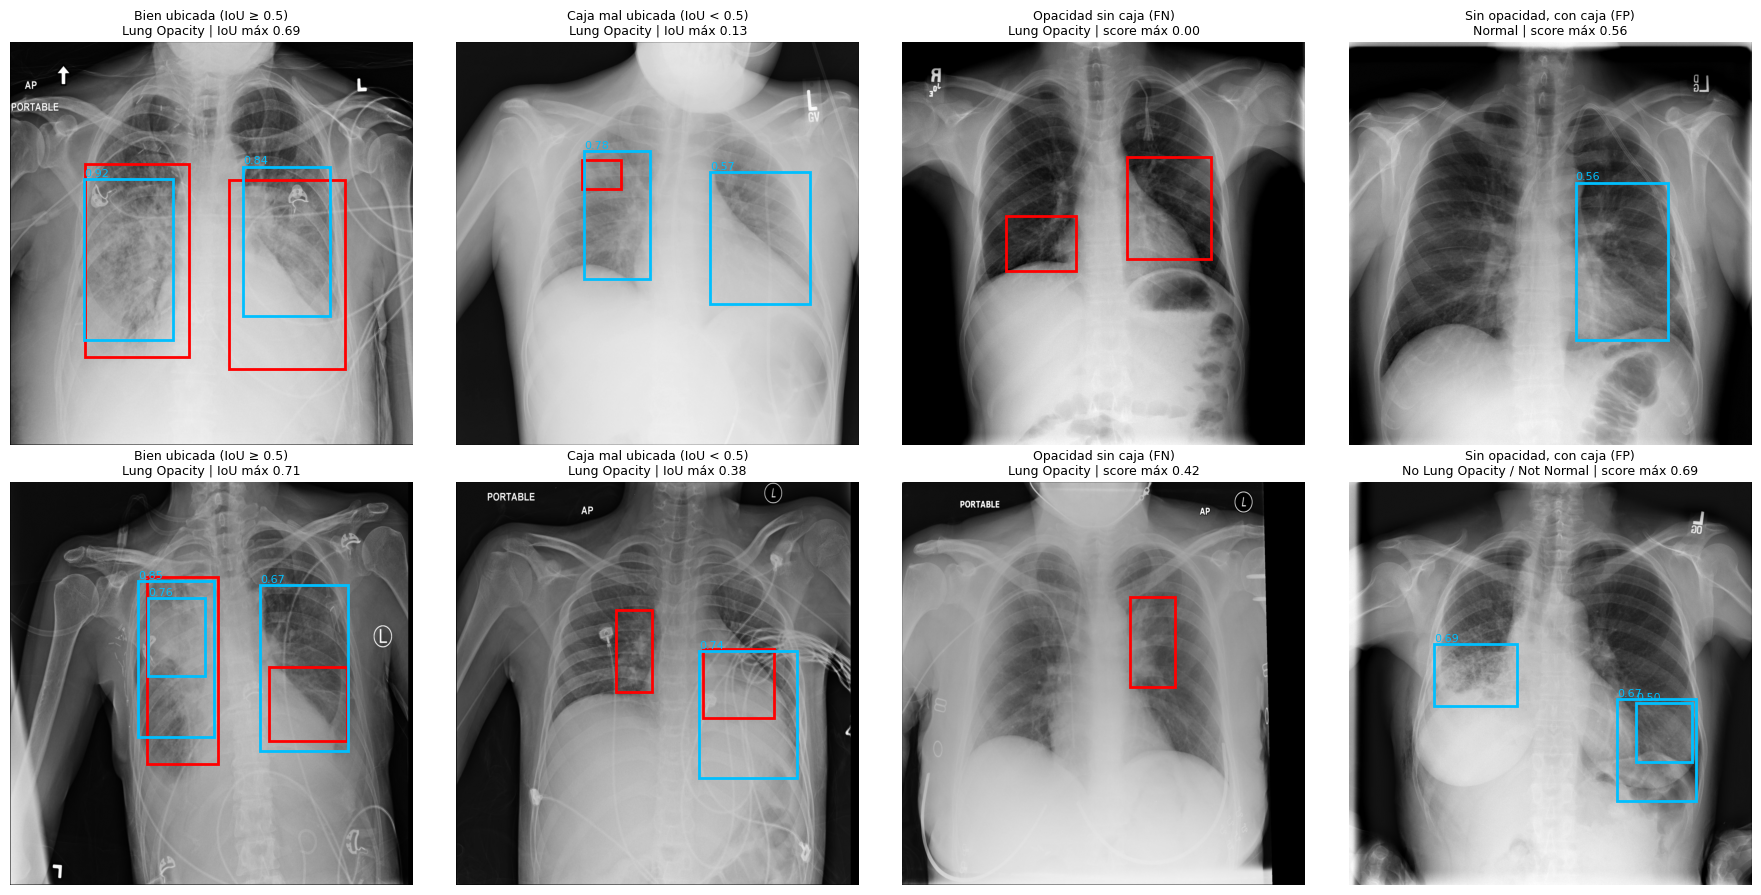

In [ ]:

def elegir(mascara, n=2):
    idx = np.flatnonzero(mascara)
    return list(np.random.default_rng(SEED).choice(idx, size=min(n, len(idx)), replace=False))

casos = [(f"Bien ubicada (IoU ≥ {IOU_MIN})", elegir(pos & localizada)),
         (f"Caja mal ubicada (IoU < {IOU_MIN})", elegir(pos & tiene_caja & ~localizada)),
         ("Opacidad sin caja (FN)", elegir(pos & ~tiene_caja)),
         ("Sin opacidad, con caja (FP)", elegir(neg & tiene_caja))]
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for col, (nombre, idxs) in enumerate(casos):
    for fila in range(2):
        ax = axes[fila, col]
        if fila >= len(idxs):
            ax.axis("off"); continue
        i = idxs[fila]; pid = pids_test[i]
        dato = f"IoU máx {iou_max[i]:.2f}" if pos[i] else f"score máx {max_test[i]:.2f}"
        if pos[i] and not tiene_caja[i]:
            dato = f"score máx {max_test[i]:.2f}"
        mostrar(pid, ax, f"{nombre}\n{CLASE[pid]} | {dato}")
        for (x1, y1, x2, y2), sc in zip(*[t.tolist() for t in preds_test[i]]):
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="deepskyblue", linewidth=2))
            ax.text(x1, y1 - 8, f"{sc:.2f}", color="deepskyblue", fontsize=8)
plt.tight_layout(); guardar_fig("07_analisis_errores_deteccion"); plt.show()

- Ejemplos de aciertos y de cada tipo de error del detector (rojo: anotación, azul: predicción).

## 6. Resumen de resultados y conclusiones

In [ ]:
c, d, k = metricas["clasificacion"], metricas["deteccion"], metricas["cascada"]
display(Markdown(f'''
| Tarea | Modelo | Métrica (test) | Valor |
|---|---|---|---|
| Clasificación | ResNet-50 | AUC | {c["auc"]:.3f} |
| | | Average precision | {c["ap"]:.3f} |
| | | Recall (sensibilidad), umbral {c["umbral"]:.2f} | {c["recall"]:.3f} |
| | | Especificidad | {c["especificidad"]:.3f} |
| | | Precisión | {c["precision"]:.3f} |
| | | F1 | {c["f1"]:.3f} |
| Detección | Faster R-CNN ResNet-50 FPN v2 | mAP@0.5 | {d["mAP@0.5"]:.3f} |
| | | mAP@[0.5:0.95] | {d["mAP"]:.3f} |
| | | Recall por caja (IoU ≥ {IOU_MIN}, emparejamiento uno a uno) | {d["recall_cajas"]:.3f} |
| | | Precisión por caja (IoU ≥ {IOU_MIN}) | {d["precision_cajas"]:.3f} |
| | | Imágenes con opacidad con ≥ 1 caja bien ubicada | {d["imagenes_con_opacidad_localizadas"]:.3f} |
| | | Imágenes sin opacidad con ≥ 1 caja (falsa alarma) | {d["imagenes_sin_opacidad_con_caja"]:.3f} |
| | | IoU medio de las parejas aceptadas (n = {d["tp"]}) | {d["iou_medio_emparejadas"]:.3f} |
'''))

json.dump(metricas, open(RES_DIR / "metricas.json", "w"), indent=2, ensure_ascii=False)
json.dump(config, open(RES_DIR / "config.json", "w"), indent=2, ensure_ascii=False)
print(json.dumps(metricas, indent=2, ensure_ascii=False))
print("Resultados, figuras y modelos guardados en:", ROOT)


| Tarea | Modelo | Métrica (test) | Valor |
|---|---|---|---|
| Clasificación | ResNet-50 | AUC | 0.872 |
| | | Average precision | 0.681 |
| | | Recall (sensibilidad), umbral 0.51 | 0.798 |
| | | Especificidad | 0.776 |
| | | Precisión | 0.506 |
| | | F1 | 0.619 |
| Detección | Faster R-CNN ResNet-50 FPN v2 | mAP@0.5 | 0.379 |
| | | mAP@[0.5:0.95] | 0.116 |
| | | Recall por caja (IoU ≥ 0.5, emparejamiento uno a uno) | 0.665 |
| | | Precisión por caja (IoU ≥ 0.5) | 0.226 |
| | | Imágenes con opacidad con ≥ 1 caja bien ubicada | 0.735 |
| | | Imágenes sin opacidad con ≥ 1 caja (falsa alarma) | 0.389 |
| | | IoU medio de las parejas aceptadas (n = 945) | 0.668 |


{
  "clasificacion": {
    "umbral": 0.508,
    "auc": 0.8718289291006914,
    "ap": 0.6807265732286911,
    "recall": 0.7984322508398656,
    "especificidad": 0.7759562841530054,
    "precision": 0.5056737588652482,
    "f1": 0.6191923577941815,
    "tp": 713.0,
    "fp": 697.0,
    "fn": 180.0,
    "tn": 2414.0
  },
  "clasificacion_umbral_0.5": {
    "umbral": 0.5,
    "auc": 0.8718289291006914,
    "ap": 0.6807265732286911,
    "recall": 0.8040313549832027,
    "especificidad": 0.7692060430729669,
    "precision": 0.5,
    "f1": 0.6165736367539717,
    "tp": 718.0,
    "fp": 718.0,
    "fn": 175.0,
    "tn": 2393.0
  },
  "clasificacion_por_clase": {
    "Lung Opacity": 79.8,
    "No Lung Opacity / Not Normal": 38.4,
    "Normal": 1.7
  },
  "clasificacion_por_posicion": {
    "AP": {
      "umbral": 0.508,
      "auc": 0.8218627378591621,
      "ap": 0.7440745139842971,
      "recall": 0.8930635838150289,
      "especificidad": 0.5191605839416058,
      "precision": 0.539737991266

- Tabla final con las métricas de test; los resultados quedan guardados en Drive.

## 7. Comparación con YOLO y NMS
- El profesor pidió comparar lo presentado con un YOLO y usar NMS para quedarnos con la mejor caja delimitadora.
- Lo presentado (el clasificador y el Faster R-CNN v1 de la sección 5) se carga desde Drive y no se modifica. Para que la comparación sea justa también se entrena un Faster R-CNN v2 con mejoras y un YOLO11s, los dos con el mismo conjunto de entrenamiento.
- Pasos: (1) NMS sobre las cajas del Faster R-CNN v1, (2) entrenar el Faster R-CNN v2, (3) entrenar YOLO11s, (4) YOLO + NMS, (5) comparar todo en el mismo test y con las mismas métricas de la sección 5, con intervalos de confianza.
- Correcciones frente a la primera versión de esta sección: el "sin NMS" no lo era, porque torchvision ya aplicaba un NMS de 0.5 dentro del modelo y YOLO uno de 0.7. Ahora los dos modelos entregan todas sus cajas y el NMS lo aplicamos nosotros con la misma función.
- Además: el NMS se elige con más imágenes de validación y con una grilla de score que llega a 0.9 (antes terminaba en 0.7 y el mejor caía justo en el borde); el mAP de las filas con NMS ya no se castiga con el tope de cajas; y el F1 por caja lleva intervalo de confianza para saber si una diferencia es real.

In [ ]:
if EN_COLAB:
    !pip install -q ultralytics

import time, shutil, math
import ultralytics
from ultralytics import YOLO
from torchvision.ops import nms
config["versiones"]["ultralytics"] = ultralytics.__version__
print("Ultralytics", ultralytics.__version__)

# ---------- Parámetros de la sección 7 (se pueden bajar si Colab va corto de tiempo) ----------
NEG_RATIO = 1.0            # negativas de entrenamiento por cada positiva (antes 0.5); mismo conjunto para Faster R-CNN v2 y YOLO
EPOCHS_DET2 = 6            # épocas del Faster R-CNN v2 (antes 3)
BATCH_DET2 = 8
LR_DET2 = 0.005
WARMUP_IT = 300            # iteraciones de calentamiento del lr; después baja con coseno
CAPAS_ENTRENABLES = 5      # capas del backbone que se ajustan (antes 3). Si falta memoria de GPU, bajar a 3
USAR_AMP = DEVICE.type == "cuda"
N_VAL_PP = 2000            # imágenes de validación para elegir el NMS (antes 1000); None = toda la validación
MAX_CRUDAS = 1000          # cajas por imagen que entrega cada modelo antes de aplicar NMS
IOU_GRID = [0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.1]
CONF_GRID = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]   # antes llegaba solo a 0.7 y el mejor caía en el borde
MAX_GRID = [100, 3, 2, 1]
PP_FRCNN_PRESENTADO = {"iou_nms": 0.5, "conf": SCORE_MIN, "max_cajas": 100}   # lo que hacía la sección 5 (NMS 0.5 interno de torchvision)
PP_YOLO_DEFECTO = {"iou_nms": 0.7, "conf": 0.25, "max_cajas": 300}            # valores por defecto de Ultralytics
config.update({"neg_ratio": NEG_RATIO, "epochs_det2": EPOCHS_DET2, "batch_det2": BATCH_DET2, "lr_det2": LR_DET2,
               "warmup_it": WARMUP_IT, "capas_entrenables_det2": CAPAS_ENTRENABLES, "amp": USAR_AMP,
               "n_val_pp": N_VAL_PP, "nms_iou_grid": IOU_GRID, "nms_conf_grid": CONF_GRID, "nms_max_cajas_grid": MAX_GRID})

# Liberamos lo que quedó de la sección 5 en memoria (el modelo se vuelve a cargar desde Drive más abajo)
for _v in ("det", "optim_det", "dl_det_train"):
    globals().pop(_v, None)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# ---------- Datos: test, validación para elegir el NMS y entrenamiento común ----------
def gt_de(pid):
    return torch.tensor(CAJAS.get(pid, []), dtype=torch.float32).reshape(-1, 4)

pids_test, y_det = test_ids["patientId"].values, test_ids["Target"].values
pos, neg = y_det == 1, y_det == 0
pasa = p_test >= UMBRAL
GT_TEST = [gt_de(p) for p in pids_test]
GT_DETVAL = [gt_de(p) for p in det_val_ids["patientId"].values]

if N_VAL_PP and N_VAL_PP < len(val_ids):
    val_pp_ids, _ = train_test_split(val_ids, train_size=N_VAL_PP, stratify=val_ids["Target"], random_state=SEED)
else:
    val_pp_ids = val_ids
val_pp_ids = val_pp_ids.reset_index(drop=True)
pids_vpp, y_vpp = val_pp_ids["patientId"].values, val_pp_ids["Target"].values
GT_VPP = [gt_de(p) for p in pids_vpp]
dl_vpp = make_loader(DetDataset(val_pp_ids), BATCH_DET, detection=True)

pos_tr2 = train_ids[train_ids["Target"] == 1]
neg_tr2 = train_ids[train_ids["Target"] == 0].sample(int(len(pos_tr2) * NEG_RATIO), random_state=SEED)
det2_train_ids = pd.concat([pos_tr2, neg_tr2]).reset_index(drop=True)
for nombre, s in [("train (Faster R-CNN v2 y YOLO)", det2_train_ids), ("val para early stopping", det_val_ids),
                  ("val para elegir el NMS", val_pp_ids), ("test", test_ids)]:
    print(f"{nombre}: {len(s)} imágenes | con opacidad: {int(s['Target'].sum())} ({100 * s['Target'].mean():.1f} %)")
config["det2_train"] = {"imagenes": len(det2_train_ids), "positivas": int(det2_train_ids["Target"].sum())}
config["val_pp"] = {"imagenes": len(val_pp_ids), "positivas": int(val_pp_ids["Target"].sum())}

# ---------- Funciones comunes ----------
def aplicar_nms(preds, iou_nms, conf=0.0, max_cajas=MAX_CRUDAS):
    # Entre cajas que se solapan más que iou_nms se queda la de mayor score; después se aplica el score mínimo y el tope de cajas
    salida = []
    for b, s in preds:
        k = nms(b, s, iou_nms) if len(b) else torch.zeros(0, dtype=torch.long)
        b, s = b[k], s[k]
        k = s >= conf
        salida.append((b[k][:max_cajas], s[k][:max_cajas]))
    return salida

def recortar(preds, conf, max_cajas):
    # Score mínimo y tope de cajas sobre cajas ya ordenadas por score (salida de aplicar_nms)
    salida = []
    for b, s in preds:
        k = s >= conf
        salida.append((b[k][:max_cajas], s[k][:max_cajas]))
    return salida

def map_de(preds, gts):
    m = MeanAveragePrecision(iou_type="bbox")
    m.update([{"boxes": b, "scores": s, "labels": torch.ones(len(b), dtype=torch.int64)} for b, s in preds],
             [{"boxes": g, "labels": torch.ones(len(g), dtype=torch.int64)} for g in gts])
    r = m.compute()
    return {"mAP@0.5": r["map_50"].item(), "mAP": r["map"].item()}

def cajas_de(preds, gts, y, filtro=None):
    # Mismo emparejamiento IoU >= IOU_MIN de la sección 5; además devuelve los conteos por imagen (para el bootstrap)
    n = len(preds); cnt = np.zeros((n, 3), dtype=int); n_pred = np.zeros(n, dtype=int); ious = []
    for i, ((b, s), gt) in enumerate(zip(preds, gts)):
        if filtro is not None and not filtro[i]:
            b, s = b[:0], s[:0]
        tp, fp, fn, iu = emparejar(b, s, gt)
        cnt[i] = (tp, fp, fn); n_pred[i] = len(b); ious += iu
    TP, FP, FN = (int(v) for v in cnt.sum(0))
    rec, prec = TP / max(TP + FN, 1), TP / max(TP + FP, 1)
    tp_img, y = cnt[:, 0], np.asarray(y)
    res = {"recall_cajas": rec, "precision_cajas": prec, "f1_cajas": 2 * rec * prec / (rec + prec) if rec + prec else 0.0,
           "imagenes_con_opacidad_localizadas": float((tp_img[y == 1] > 0).mean()),
           "imagenes_sin_opacidad_con_caja": float((n_pred[y == 0] > 0).mean()),
           "cajas_por_imagen_con_opacidad": float(n_pred[y == 1].mean()),
           "iou_medio_emparejadas": float(np.mean(ious)) if ious else float("nan"),
           "tp": TP, "fp": FP, "fn": FN}
    return res, tp_img, n_pred, cnt

def buscar_postproceso(preds, gts, y):
    # Prueba NMS x score mínimo x tope de cajas y se queda con el mejor F1 por caja
    filas = []
    for iou_ in tqdm(IOU_GRID, desc="Búsqueda de NMS", leave=False):
        base = aplicar_nms(preds, iou_)
        for c in CONF_GRID:
            filtradas = recortar(base, c, max(MAX_GRID))
            for mx in MAX_GRID:
                r, _, _, _ = cajas_de(recortar(filtradas, 0.0, mx), gts, y)
                filas.append({"iou_nms": iou_, "conf": c, "max_cajas": mx, **r})
    tabla = pd.DataFrame(filas)
    m = tabla.loc[tabla["f1_cajas"].idxmax()]
    return tabla, {"iou_nms": float(m["iou_nms"]), "conf": float(m["conf"]), "max_cajas": int(m["max_cajas"])}

def auc_score_max(preds, y):
    return float(roc_auc_score(y, [s.max().item() if len(s) else 0.0 for _, s in preds]))

def f1_boot(cnt, B=2000, seed=SEED):
    # F1 por caja remuestreando imágenes con reemplazo (misma semilla = mismas imágenes remuestreadas en todos los modelos)
    idx = np.random.default_rng(seed).integers(0, len(cnt), size=(B, len(cnt)))
    tp, fp, fn = (cnt[idx, k].sum(1) for k in range(3))
    rec, prec = tp / np.maximum(tp + fn, 1), tp / np.maximum(tp + fp, 1)
    return np.where(rec + prec > 0, 2 * rec * prec / np.maximum(rec + prec, 1e-12), 0.0)

def construir_frcnn(capas):
    # Sin NMS interno (box_nms_thresh=1.0) y con score mínimo casi nulo: el modelo entrega todas sus cajas y el NMS lo aplicamos nosotros
    m = fasterrcnn_resnet50_fpn_v2(weights="DEFAULT", min_size=DET_SIZE, max_size=DET_SIZE, trainable_backbone_layers=capas,
                                   box_score_thresh=0.001, box_nms_thresh=1.0, box_detections_per_img=MAX_CRUDAS)
    m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, 2)
    return m.to(DEVICE)

@torch.no_grad()
def predecir_frcnn(m, dl):
    gc.collect(); m.eval(); preds = []; t0 = time.perf_counter()
    for imgs, _ in tqdm(dl, desc="Faster R-CNN", leave=False):
        for s in m([i.to(DEVICE) for i in imgs]):
            preds.append((s["boxes"].cpu(), s["scores"].cpu()))
    return preds, 1000 * (time.perf_counter() - t0) / len(dl.dataset)

COLS_GRID = ["iou_nms", "conf", "max_cajas", "f1_cajas", "recall_cajas", "precision_cajas",
             "imagenes_con_opacidad_localizadas", "imagenes_sin_opacidad_con_caja"]

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.215
train (Faster R-CNN v2 y YOLO): 8452 imágenes | con opacidad: 4226 (50.0 %)
val para early stopping: 1000 imágenes | con opacidad: 223 (22.3 %)
val para elegir el NMS: 2000 imágenes | con opacidad: 446 (22.3 %)
test: 4004 imágenes | con opacidad: 893 (22.3 %)


- NMS (non-maximum suppression): cuando dos cajas se solapan más que un umbral de IoU, se queda la de mayor score y se borra la otra. Con 0.5 funciona el de torchvision y con 0.7 el de Ultralytics; aquí se prueban de 0.7 a 0.1.
- Además del umbral de NMS probamos un score mínimo (0.1 a 0.9) y un máximo de cajas por imagen (las imágenes reales tienen de 1 a 4 cajas, casi siempre 1 o 2).
- Las tres cosas se eligen en validación con el F1 por caja (mismo emparejamiento IoU ≥ 0.5 de la sección 5). El test solo se usa al final.
- Parámetros de la sección: al inicio de la celda están las épocas, el tamaño de la validación y la proporción de negativas; se pueden bajar si Colab va corto de tiempo.

In [ ]:
det1 = construir_frcnn(capas=3)
det1.load_state_dict(cargar(RUTA_DET)["modelo"])
params_frcnn1 = sum(p.numel() for p in det1.parameters()) / 1e6
frcnn1_val, _ = predecir_frcnn(det1, dl_vpp)
frcnn1_test, ms_frcnn1 = predecir_frcnn(det1, dl_det_test)
del det1
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print(f"Cajas crudas por imagen en test: {np.mean([len(b) for b, _ in frcnn1_test]):.0f}")

# Control: NMS 0.5 y score mínimo sobre las cajas crudas debe reproducir los números de la sección 5
ctrl, _, _, _ = cajas_de(aplicar_nms(frcnn1_test, **PP_FRCNN_PRESENTADO), GT_TEST, y_det)
map_ctrl = map_de(aplicar_nms(frcnn1_test, 0.5, 0.05, 100), GT_TEST)
print(f"Control (debe coincidir con la sección 5): mAP@0.5 {map_ctrl['mAP@0.5']:.3f} vs {metricas['deteccion']['mAP@0.5']:.3f} | "
      f"recall por caja {ctrl['recall_cajas']:.3f} vs {metricas['deteccion']['recall_cajas']:.3f} | "
      f"precisión por caja {ctrl['precision_cajas']:.3f} vs {metricas['deteccion']['precision_cajas']:.3f}")

grid_frcnn1, pp_frcnn1 = buscar_postproceso(frcnn1_val, GT_VPP, y_vpp)
grid_frcnn1.to_csv(RES_DIR / "nms_grid_fasterrcnn_v1.csv", index=False)
config["postproceso_fasterrcnn_v1"] = pp_frcnn1
print("Post-proceso elegido en validación para Faster R-CNN v1:", pp_frcnn1)
display(grid_frcnn1.sort_values("f1_cajas", ascending=False)[COLS_GRID].head(8).round(3))

Faster R-CNN:   0%|          | 0/250 [00:00<?, ?it/s]

Faster R-CNN:   0%|          | 0/501 [00:00<?, ?it/s]

Cajas crudas por imagen en test: 517
Control (debe coincidir con la sección 5): mAP@0.5 0.379 vs 0.379 | recall por caja 0.665 vs 0.665 | precisión por caja 0.226 vs 0.226


Búsqueda de NMS:   0%|          | 0/7 [00:00<?, ?it/s]

Post-proceso elegido en validación para Faster R-CNN v1: {'iou_nms': 0.5, 'conf': 0.7, 'max_cajas': 3}


,iou_nms,conf,max_cajas,f1_cajas,recall_cajas,precision_cajas,imagenes_con_opacidad_localizadas,imagenes_sin_opacidad_con_caja
97,0.5,0.7,3,0.432,0.518,0.371,0.599,0.199
96,0.5,0.7,100,0.432,0.518,0.371,0.599,0.199
244,0.1,0.8,100,0.432,0.366,0.527,0.417,0.072
245,0.1,0.8,3,0.432,0.366,0.527,0.417,0.072
210,0.2,0.8,2,0.432,0.366,0.527,0.417,0.072
208,0.2,0.8,100,0.432,0.366,0.527,0.417,0.072
209,0.2,0.8,3,0.432,0.366,0.527,0.417,0.072
246,0.1,0.8,2,0.432,0.366,0.527,0.417,0.072


- Faster R-CNN v1 (el de la sección 5) se carga desde Drive, pero ahora entrega todas sus cajas (hasta 1000 por imagen, sin NMS interno), y el NMS se aplica después con la misma función para todos los modelos.
- El control confirma que NMS 0.5 y score ≥ 0.5 sobre esas cajas reproduce los números de la sección 5.
- La tabla muestra las mejores combinaciones de NMS, score mínimo y máximo de cajas en validación.

Retomando desde Drive: 6 de 6 épocas ya entrenadas


,epoca,lr,loss_classifier,loss_box_reg,loss_objectness,loss_rpn_box_reg,mAP@0.5,mAP
0,1,0.0048,0.0770,0.0813,0.0173,0.0032,0.3660,0.1225
1,2,0.0040,0.0613,0.0798,0.0087,0.0026,0.4153,0.1336
2,3,0.0027,0.0577,0.0767,0.0075,0.0025,0.4157,0.1265
3,4,0.0014,0.0533,0.0731,0.0063,0.0024,0.3928,0.1314
4,5,0.0004,0.0480,0.0689,0.0050,0.0023,0.3801,0.1264
5,6,0.0000,0.0428,0.0640,0.0040,0.0022,0.3949,0.1353


Mejor época (mAP@0.5 de validación): 3


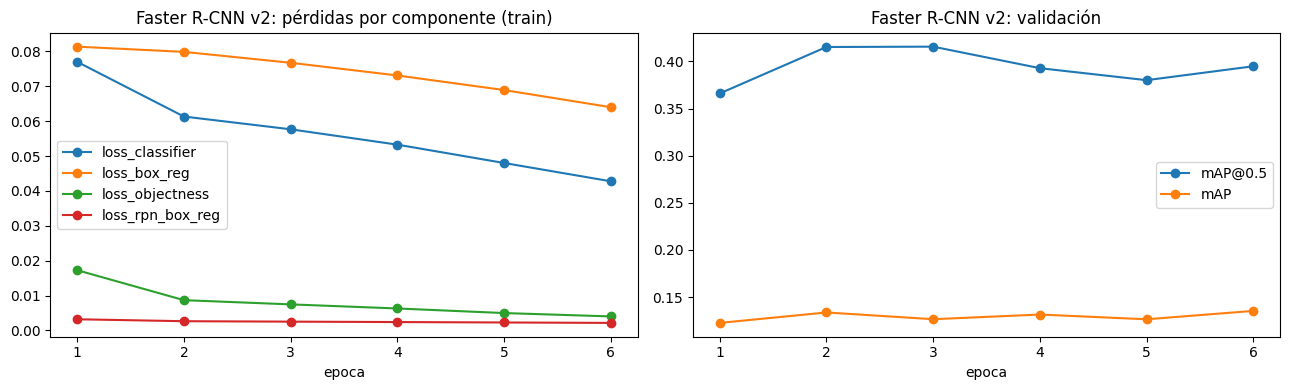

Faster R-CNN:   0%|          | 0/250 [00:00<?, ?it/s]

Faster R-CNN:   0%|          | 0/501 [00:00<?, ?it/s]

Cajas crudas por imagen en test: 364


Búsqueda de NMS:   0%|          | 0/7 [00:00<?, ?it/s]

Post-proceso elegido en validación para Faster R-CNN v2: {'iou_nms': 0.5, 'conf': 0.8, 'max_cajas': 100}


,iou_nms,conf,max_cajas,f1_cajas,recall_cajas,precision_cajas,imagenes_con_opacidad_localizadas,imagenes_sin_opacidad_con_caja
101,0.5,0.8,3,0.454,0.384,0.555,0.457,0.069
100,0.5,0.8,100,0.454,0.384,0.555,0.457,0.069
137,0.4,0.8,3,0.453,0.383,0.556,0.457,0.069
136,0.4,0.8,100,0.453,0.383,0.556,0.457,0.069
210,0.2,0.8,2,0.452,0.380,0.558,0.457,0.069
208,0.2,0.8,100,0.452,0.380,0.558,0.457,0.069
209,0.2,0.8,3,0.452,0.380,0.558,0.457,0.069
172,0.3,0.8,100,0.452,0.380,0.558,0.457,0.069


In [ ]:
class DetDataset2(Dataset):
    # Igual que DetDataset de la sección 5, con un poco de variación de brillo y contraste (placas de distintos equipos)
    def __init__(self, tabla, aug=False):
        self.ids, self.aug = tabla["patientId"].values, aug
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        pid = self.ids[i]
        with Image.open(img_paths[pid]) as im:
            img = TF.to_tensor(im.convert("RGB"))
        cajas = torch.tensor(CAJAS.get(pid, []), dtype=torch.float32).reshape(-1, 4)
        if self.aug:
            if random.random() < 0.5:
                img = img.flip(-1)
                cajas[:, [0, 2]] = img.shape[-1] - cajas[:, [2, 0]]
            if random.random() < 0.8:
                img = TF.adjust_contrast(img, random.uniform(0.8, 1.2))
                img = TF.adjust_brightness(img, random.uniform(0.85, 1.15)).clamp(0, 1)
        return img, {"boxes": cajas, "labels": torch.ones(len(cajas), dtype=torch.int64)}

RUTA_DET2 = MODEL_DIR / "detector_fasterrcnn_v2.pt"
RUTA_DET2_ULT = MODEL_DIR / "detector_v2_ultimo.pt"

det2 = construir_frcnn(capas=CAPAS_ENTRENABLES)
params_train = [p for p in det2.parameters() if p.requires_grad]
optim2 = torch.optim.SGD(params_train, lr=LR_DET2, momentum=0.9, weight_decay=1e-4)
dl_det2_train = make_loader(DetDataset2(det2_train_ids, aug=True), BATCH_DET2, shuffle=True, detection=True)
total_it = EPOCHS_DET2 * len(dl_det2_train)

def lr_lambda(it):
    # Calentamiento lineal y luego bajada con coseno hasta el 1 % del lr inicial
    if it < WARMUP_IT:
        return 0.001 + 0.999 * it / WARMUP_IT
    p = min((it - WARMUP_IT) / max(1, total_it - WARMUP_IT), 1.0)
    return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * p))

sched2 = torch.optim.lr_scheduler.LambdaLR(optim2, lr_lambda)
scaler2 = torch.amp.GradScaler("cuda", enabled=USAR_AMP)

def evaluar_v2(m):
    pr, _ = predecir_frcnn(m, dl_det_val)
    return map_de(aplicar_nms(pr, 0.5, 0.05, 100), GT_DETVAL)

mejor_map2, mejor_ep_det2, hist_det2, inicio = -float("inf"), None, [], 0
if RUTA_DET2_ULT.exists():
    ck = cargar(RUTA_DET2_ULT)
    det2.load_state_dict(ck["modelo"]); optim2.load_state_dict(ck["optim"])
    sched2.load_state_dict(ck["sched"]); scaler2.load_state_dict(ck["scaler"])
    mejor_map2, mejor_ep_det2, hist_det2, inicio = ck["mejor_map"], ck["mejor_ep"], ck["historial"], ck["epoca"]
    del ck
    print(f"Retomando desde Drive: {inicio} de {EPOCHS_DET2} épocas ya entrenadas")

for ep in range(inicio, EPOCHS_DET2):
    gc.collect(); det2.train(); suma = {}; saltadas = 0
    for imgs, tgts in tqdm(dl_det2_train, desc=f"Época {ep + 1}/{EPOCHS_DET2}"):
        imgs = [i.to(DEVICE) for i in imgs]
        tgts = [{k: v.to(DEVICE) for k, v in t.items()} for t in tgts]
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USAR_AMP):
            partes = det2(imgs, tgts)
            loss = sum(partes.values())
        if not torch.isfinite(loss):
            optim2.zero_grad(set_to_none=True); saltadas += 1
            continue
        optim2.zero_grad(set_to_none=True)
        scaler2.scale(loss).backward()
        scaler2.unscale_(optim2)
        torch.nn.utils.clip_grad_norm_(params_train, 10.0)
        scaler2.step(optim2); scaler2.update(); sched2.step()
        for k, v in partes.items():
            suma[k] = suma.get(k, 0) + v.item()
    r = evaluar_v2(det2)
    hist_det2.append({"epoca": ep + 1, "lr": optim2.param_groups[0]["lr"],
                      **{k: v / max(len(dl_det2_train) - saltadas, 1) for k, v in suma.items()}, **r})
    print({k: round(v, 5) if k == "lr" else round(v, 4) for k, v in hist_det2[-1].items()}, f"| iteraciones saltadas: {saltadas}")
    if r["mAP@0.5"] > mejor_map2:
        mejor_map2, mejor_ep_det2 = r["mAP@0.5"], ep + 1
        guardar_ck({"modelo": det2.state_dict(), "epoca": ep + 1}, RUTA_DET2)
    guardar_ck({"modelo": det2.state_dict(), "optim": optim2.state_dict(), "sched": sched2.state_dict(),
                "scaler": scaler2.state_dict(), "epoca": ep + 1, "historial": hist_det2, "mejor_map": mejor_map2,
                "mejor_ep": mejor_ep_det2, "config": config_simple()}, RUTA_DET2_ULT)
hd2 = pd.DataFrame(hist_det2)
display(hd2.round(4))
print("Mejor época (mAP@0.5 de validación):", mejor_ep_det2)
config["mejor_epoca_det2"] = mejor_ep_det2
hd2.to_csv(RES_DIR / "historial_deteccion_v2.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
hd2.plot(x="epoca", y=[c for c in ["loss_classifier", "loss_box_reg", "loss_objectness", "loss_rpn_box_reg"] if c in hd2], ax=ax[0], marker="o", title="Faster R-CNN v2: pérdidas por componente (train)")
hd2.plot(x="epoca", y=["mAP@0.5", "mAP"], ax=ax[1], marker="o", title="Faster R-CNN v2: validación")
plt.tight_layout(); guardar_fig("12_curvas_deteccion_v2"); plt.show()

# Mejor época: cajas crudas en validación (para elegir el NMS) y en test
det2.load_state_dict(cargar(RUTA_DET2)["modelo"])
params_frcnn2 = sum(p.numel() for p in det2.parameters()) / 1e6
frcnn2_val, _ = predecir_frcnn(det2, dl_vpp)
frcnn2_test, ms_frcnn2 = predecir_frcnn(det2, dl_det_test)
del det2, optim2, sched2, scaler2, dl_det2_train, params_train
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print(f"Cajas crudas por imagen en test: {np.mean([len(b) for b, _ in frcnn2_test]):.0f}")

grid_frcnn2, pp_frcnn2 = buscar_postproceso(frcnn2_val, GT_VPP, y_vpp)
grid_frcnn2.to_csv(RES_DIR / "nms_grid_fasterrcnn_v2.csv", index=False)
config["postproceso_fasterrcnn_v2"] = pp_frcnn2
print("Post-proceso elegido en validación para Faster R-CNN v2:", pp_frcnn2)
display(grid_frcnn2.sort_values("f1_cajas", ascending=False)[COLS_GRID].head(8).round(3))

- Faster R-CNN v2: mismo modelo y mismo punto de partida (COCO), con estos cambios: entrenamiento con 50 % de imágenes con opacidad (antes 67 %, y en test es 22 %, lo que inflaba las falsas alarmas), 6 épocas en vez de 3 con el lr subiendo al inicio y bajando con coseno, precisión mixta (AMP) para ir más rápido, más capas del backbone entrenables y variación de brillo y contraste además del volteo.
- Se guarda la mejor época según el mAP@0.5 de 1000 imágenes de validación. Los archivos se guardan con otros nombres en Drive y el v1 no se toca.
- Después se sacan sus cajas crudas en validación y test y se elige su NMS igual que con el v1.

YOLO train:   0%|          | 0/8452 [00:00<?, ?it/s]

YOLO train: 8452 imágenes, 6713 cajas


YOLO val:   0%|          | 0/1000 [00:00<?, ?it/s]

YOLO val: 1000 imágenes, 357 cajas
yolo11s: retomando desde Drive
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/yolo_rsna_v2_neg1.0/rsna.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=None, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/proyecto_neumonia/v3/mode

YOLO:   0%|          | 0/63 [00:00<?, ?it/s]

YOLO:   0%|          | 0/126 [00:00<?, ?it/s]

Cajas crudas por imagen en test: 105


,parámetros (M),épocas,ms por imagen,val mAP@0.5,val mAP,min. entrenamiento
Faster R-CNN v1,43.256,3.0,92.026,0.420,0.127,NaN
Faster R-CNN v2,43.256,6.0,92.087,0.423,0.134,NaN
yolo11s,9.428,25.0,24.350,0.391,0.157,28.288


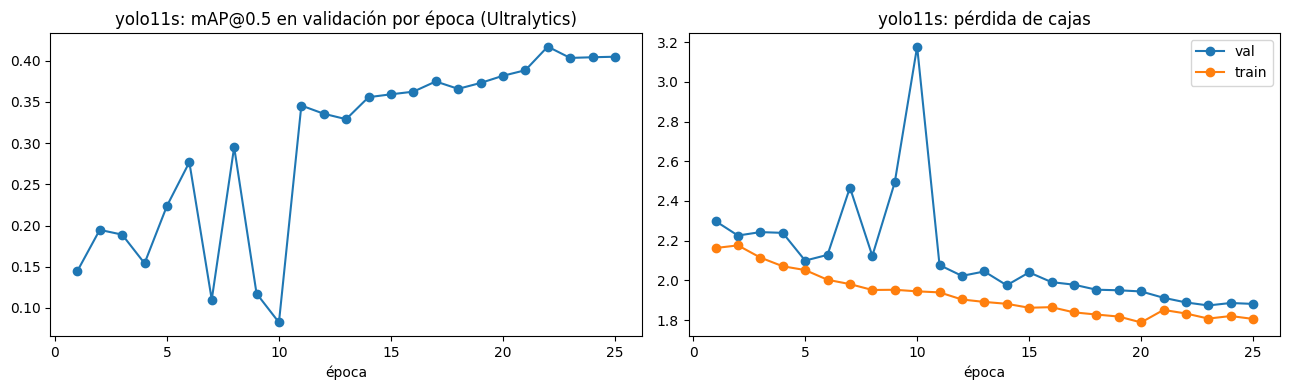

In [ ]:
YOLO_SIZE = DET_SIZE
YOLO_DATA = Path("/content") / f"yolo_rsna_v2_neg{NEG_RATIO}" if EN_COLAB else ROOT / f"yolo_rsna_v2_neg{NEG_RATIO}"

def preparar_split(nombre, tabla):
    d_img, d_lab = YOLO_DATA / "images" / nombre, YOLO_DATA / "labels" / nombre
    d_img.mkdir(parents=True, exist_ok=True); d_lab.mkdir(parents=True, exist_ok=True)
    for pid in tqdm(tabla["patientId"].values, desc=f"YOLO {nombre}"):
        destino = d_img / f"{pid}.png"
        if not destino.exists():
            with Image.open(img_paths[pid]) as im:
                im.convert("L").resize((YOLO_SIZE, YOLO_SIZE), Image.BILINEAR).save(destino)
        lineas = [f"0 {(x1 + x2) / 2 / IMG_W:.6f} {(y1 + y2) / 2 / IMG_H:.6f} {(x2 - x1) / IMG_W:.6f} {(y2 - y1) / IMG_H:.6f}"
                  for x1, y1, x2, y2 in CAJAS.get(pid, [])]
        (d_lab / f"{pid}.txt").write_text("\n".join(lineas))
    return len(list(d_img.glob("*.png"))), sum(len(CAJAS.get(p, [])) for p in tabla["patientId"])

for nombre, tabla in [("train", det2_train_ids), ("val", det_val_ids)]:
    n_img, n_cj = preparar_split(nombre, tabla)
    print(f"YOLO {nombre}: {n_img} imágenes, {n_cj} cajas")
DATA_YAML = YOLO_DATA / "rsna.yaml"
DATA_YAML.write_text(f"path: {YOLO_DATA}\ntrain: images/train\nval: images/val\nnames:\n  0: opacidad\n")

YOLO_ELEGIDO = "yolo11s"      # solo el tamaño small, por tiempo de entrenamiento
EPOCHS_YOLO = 25              # antes 20
BATCH_YOLO = 16
PATIENCE_YOLO = 10
YOLO_DIR = MODEL_DIR / "yolo_v2"
if REENTRENAR and YOLO_DIR.exists():
    shutil.rmtree(YOLO_DIR)
ARGS_YOLO = dict(cos_lr=True, mosaic=0.5, close_mosaic=5, scale=0.3, translate=0.05)   # ajustes para radiografías
config.update({"yolo_elegido": YOLO_ELEGIDO, "epochs_yolo": EPOCHS_YOLO, "batch_yolo": BATCH_YOLO,
               "patience_yolo": PATIENCE_YOLO, "yolo_size": YOLO_SIZE, "yolo_args": ARGS_YOLO})

def entrenar_yolo(nombre):
    carpeta = YOLO_DIR / nombre
    last, fin = carpeta / "weights" / "last.pt", carpeta / "terminado.txt"
    if fin.exists():
        print(f"{nombre}: ya entrenado, se carga desde Drive")
    else:
        if last.exists():
            print(f"{nombre}: retomando desde Drive")
            try:
                YOLO(str(last)).train(resume=True)
            except AssertionError as e:
                print(e)
        else:
            YOLO(f"{nombre}.pt").train(data=str(DATA_YAML), epochs=EPOCHS_YOLO, imgsz=YOLO_SIZE, batch=BATCH_YOLO,
                                       patience=PATIENCE_YOLO, project=str(YOLO_DIR), name=nombre, exist_ok=True,
                                       seed=SEED, deterministic=True, workers=NUM_WORKERS, verbose=False, **ARGS_YOLO)
        fin.write_text("ok")
    return carpeta / "weights" / "best.pt"

def predecir_yolo(m, pids, lote=32):
    # iou=1.0 desactiva el NMS interno de Ultralytics: entrega todas sus cajas y el NMS lo aplicamos nosotros
    preds = []; t0 = time.perf_counter()
    for i in tqdm(range(0, len(pids), lote), desc="YOLO", leave=False):
        rutas = [str(img_paths[p]) for p in pids[i:i + lote]]
        for r in m.predict(rutas, imgsz=YOLO_SIZE, conf=0.001, iou=1.0, max_det=MAX_CRUDAS, batch=lote, verbose=False):
            preds.append((r.boxes.xyxy.cpu().float(), r.boxes.conf.cpu().float()))
    return preds, 1000 * (time.perf_counter() - t0) / len(pids)

m_y = YOLO(str(entrenar_yolo(YOLO_ELEGIDO)))
yolo_val, _ = predecir_yolo(m_y, pids_vpp)
yolo_test, ms_yolo = predecir_yolo(m_y, pids_test)
params_yolo = sum(p.numel() for p in m_y.model.parameters()) / 1e6
del m_y; gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print(f"Cajas crudas por imagen en test: {np.mean([len(b) for b, _ in yolo_test]):.0f}")

h = pd.read_csv(YOLO_DIR / YOLO_ELEGIDO / "results.csv"); h.columns = h.columns.str.strip()
minutos = h["time"].iloc[-1] / 60 if "time" in h else np.nan
val_modelos = pd.DataFrame({
    "Faster R-CNN v1": {"parámetros (M)": params_frcnn1, "épocas": EPOCHS_DET, "ms por imagen": ms_frcnn1,
                        **{f"val {k}": v for k, v in map_de(aplicar_nms(frcnn1_val, 0.5, 0.05, 100), GT_VPP).items()}},
    "Faster R-CNN v2": {"parámetros (M)": params_frcnn2, "épocas": EPOCHS_DET2, "ms por imagen": ms_frcnn2,
                        **{f"val {k}": v for k, v in map_de(aplicar_nms(frcnn2_val, 0.5, 0.05, 100), GT_VPP).items()}},
    YOLO_ELEGIDO: {"parámetros (M)": params_yolo, "épocas": len(h), "ms por imagen": ms_yolo, "min. entrenamiento": minutos,
                   **{f"val {k}": v for k, v in map_de(aplicar_nms(yolo_val, 0.7, 0.001, 300), GT_VPP).items()}}}).T
display(val_modelos.round(3)); val_modelos.to_csv(RES_DIR / "val_modelos.csv")
metricas["val_modelos"] = val_modelos.reset_index().to_dict(orient="records")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(h["epoch"], h["metrics/mAP50(B)"], marker="o"); ax[0].set_title(f"{YOLO_ELEGIDO}: mAP@0.5 en validación por época (Ultralytics)")
ax[1].plot(h["epoch"], h["val/box_loss"], marker="o", label="val"); ax[1].plot(h["epoch"], h["train/box_loss"], marker="o", label="train")
ax[1].set_title(f"{YOLO_ELEGIDO}: pérdida de cajas"); ax[1].legend()
for a in ax:
    a.set_xlabel("época")
plt.tight_layout(); guardar_fig("08_yolo_entrenamiento"); plt.show()

- YOLO11s (tamaño small), preentrenado en COCO, con exactamente las mismas imágenes de entrenamiento que el Faster R-CNN v2 y el mismo tamaño de 512; las negativas llevan un archivo de etiquetas vacío. Los modelos más grandes tardan demasiado en Colab.
- Cambios frente a la primera versión: 25 épocas (antes 20), lr con coseno, mosaico a la mitad y menos escala y traslación, porque las radiografías compuestas por mosaico son poco realistas y el tamaño de la opacidad es información importante.
- YOLO también entrega todas sus cajas (iou=1.0 desactiva su NMS interno). La tabla compara los modelos en validación con las mismas imágenes y el mismo cálculo de mAP.
- Si Colab se desconecta, el YOLO sigue desde la última época guardada en Drive.

In [ ]:
grid_yolo, pp_yolo = buscar_postproceso(yolo_val, GT_VPP, y_vpp)
grid_yolo.to_csv(RES_DIR / f"nms_grid_{YOLO_ELEGIDO}.csv", index=False)
config["postproceso_yolo"] = pp_yolo
print(f"Post-proceso elegido en validación para {YOLO_ELEGIDO}:", pp_yolo)
display(grid_yolo.sort_values("f1_cajas", ascending=False)[COLS_GRID].head(8).round(3))

MODELOS = {
    "Faster R-CNN v1 (presentado)": (frcnn1_test, PP_FRCNN_PRESENTADO, ms_frcnn1, params_frcnn1),
    "Faster R-CNN v1 + NMS": (frcnn1_test, pp_frcnn1, ms_frcnn1, params_frcnn1),
    "Faster R-CNN v2 (mismo post-proceso)": (frcnn2_test, PP_FRCNN_PRESENTADO, ms_frcnn2, params_frcnn2),
    "Faster R-CNN v2 + NMS": (frcnn2_test, pp_frcnn2, ms_frcnn2, params_frcnn2),
    f"{YOLO_ELEGIDO} (por defecto)": (yolo_test, PP_YOLO_DEFECTO, ms_yolo, params_yolo),
    f"{YOLO_ELEGIDO} + NMS": (yolo_test, pp_yolo, ms_yolo, params_yolo),
}
comparacion, finales, n_pred_mod, cnt_mod = {}, {}, {}, {}
for nombre, (preds, pp, ms, prm) in MODELOS.items():
    finales[nombre] = aplicar_nms(preds, pp["iou_nms"], pp["conf"], pp["max_cajas"])
    solo, _, n_pred_mod[nombre], cnt_mod[nombre] = cajas_de(finales[nombre], GT_TEST, y_det)
    casc, _, _, _ = cajas_de(finales[nombre], GT_TEST, y_det, filtro=pasa)
    # El mAP ya recorre todos los scores: solo se le aplica el NMS del modelo (sin score mínimo ni tope de cajas)
    comparacion[nombre] = {**map_de(aplicar_nms(preds, pp["iou_nms"], 0.0, 100), GT_TEST), **solo,
                           "cascada_localizadas": casc["imagenes_con_opacidad_localizadas"],
                           "cascada_falsas_alarmas": casc["imagenes_sin_opacidad_con_caja"],
                           "auc_score_max": auc_score_max(preds, y_det), "ms_por_imagen": ms, "parametros_M": prm,
                           "postproceso": f"NMS {pp['iou_nms']} · score ≥ {pp['conf']} · máx {pp['max_cajas']} cajas"}

NOMBRES_COMP = {**NOMBRES, "mAP@0.5": "mAP@0.5", "mAP": "mAP@[0.5:0.95]", "f1_cajas": f"F1 por caja (IoU ≥ {IOU_MIN})",
                "cajas_por_imagen_con_opacidad": "Cajas predichas por imagen con opacidad",
                "cascada_localizadas": "Cascada: imágenes con opacidad localizadas",
                "cascada_falsas_alarmas": "Cascada: imágenes sin opacidad con caja",
                "auc_score_max": "AUC usando el score máximo como clasificador",
                "ms_por_imagen": "ms por imagen (aprox.)", "parametros_M": "Parámetros (millones)", "postproceso": "Post-proceso"}
tabla_comp = pd.DataFrame(comparacion)
tabla_comp.to_csv(RES_DIR / "comparacion_yolo_nms.csv")
metricas["comparacion_yolo_nms"] = comparacion
print(f"Cajas reales por imagen con opacidad en test: {np.mean([len(CAJAS[p]) for p in pids_test[pos]]):.2f}")
display(tabla_comp.rename(index=NOMBRES_COMP).map(lambda v: round(v, 3) if isinstance(v, float) else v))

Búsqueda de NMS:   0%|          | 0/7 [00:00<?, ?it/s]

Post-proceso elegido en validación para yolo11s: {'iou_nms': 0.3, 'conf': 0.1, 'max_cajas': 2}


,iou_nms,conf,max_cajas,f1_cajas,recall_cajas,precision_cajas,imagenes_con_opacidad_localizadas,imagenes_sin_opacidad_con_caja
146,0.3,0.1,2,0.434,0.523,0.370,0.605,0.212
182,0.2,0.1,2,0.433,0.522,0.370,0.603,0.212
218,0.1,0.1,2,0.433,0.522,0.370,0.603,0.212
216,0.1,0.1,100,0.432,0.522,0.369,0.603,0.212
217,0.1,0.1,3,0.432,0.522,0.369,0.603,0.212
109,0.4,0.1,3,0.432,0.543,0.359,0.626,0.212
180,0.2,0.1,100,0.432,0.522,0.368,0.603,0.212
181,0.2,0.1,3,0.432,0.522,0.368,0.603,0.212


Cajas reales por imagen con opacidad en test: 1.59


,Faster R-CNN v1 (presentado),Faster R-CNN v1 + NMS,Faster R-CNN v2 (mismo post-proceso),Faster R-CNN v2 + NMS,yolo11s (por defecto),yolo11s + NMS
mAP@0.5,0.381,0.381,0.402,0.402,0.355,0.364
mAP@[0.5:0.95],0.117,0.117,0.134,0.134,0.141,0.128
Recall por caja (IoU ≥ 0.5),0.665,0.53,0.646,0.382,0.28,0.525
Precisión por caja (IoU ≥ 0.5),0.226,0.358,0.271,0.509,0.527,0.363
F1 por caja (IoU ≥ 0.5),0.338,0.428,0.382,0.437,0.365,0.43
Imágenes con opacidad con ≥ 1 caja bien ubicada,0.735,0.597,0.72,0.461,0.319,0.598
Imágenes sin opacidad con alguna caja (falsa alarma),0.389,0.201,0.298,0.076,0.044,0.206
Cajas predichas por imagen con opacidad,2.289,1.362,2.066,0.868,0.634,1.34
IoU medio de las parejas aceptadas,0.668,0.671,0.689,0.69,0.72,0.706
TP (cajas),945,752,917,543,397,746


- Con YOLO se busca el mejor NMS en validación, igual que con los Faster R-CNN.
- La tabla compara en el mismo test: el Faster R-CNN v1 tal como se presentó (NMS 0.5, score ≥ 0.5), el v1 con el NMS elegido, el v2 con la misma configuración del presentado (para ver el efecto del entrenamiento) y con su NMS elegido, y YOLO con su configuración por defecto (NMS 0.7, score ≥ 0.25) y con el NMS elegido.
- La cascada usa el mismo clasificador y umbral de la sección 4: solo se buscan cajas en las imágenes que el clasificador marca.
- "Cajas predichas por imagen con opacidad" se compara con las cajas reales (1.59 en promedio): si es mucho mayor, el modelo repite cajas; si es menor, se le escapan opacidades.

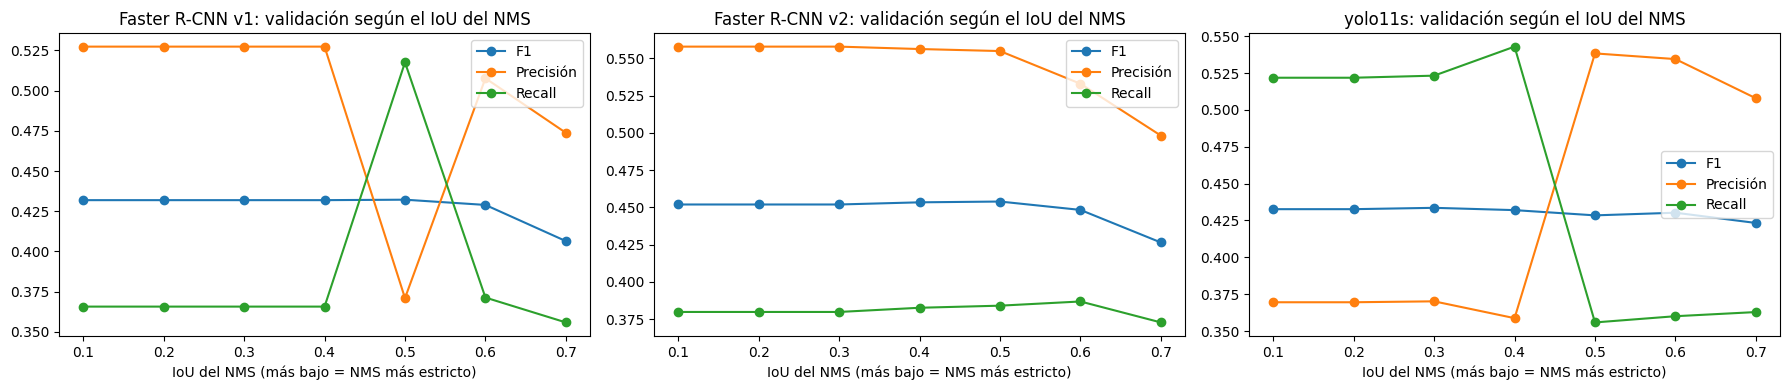

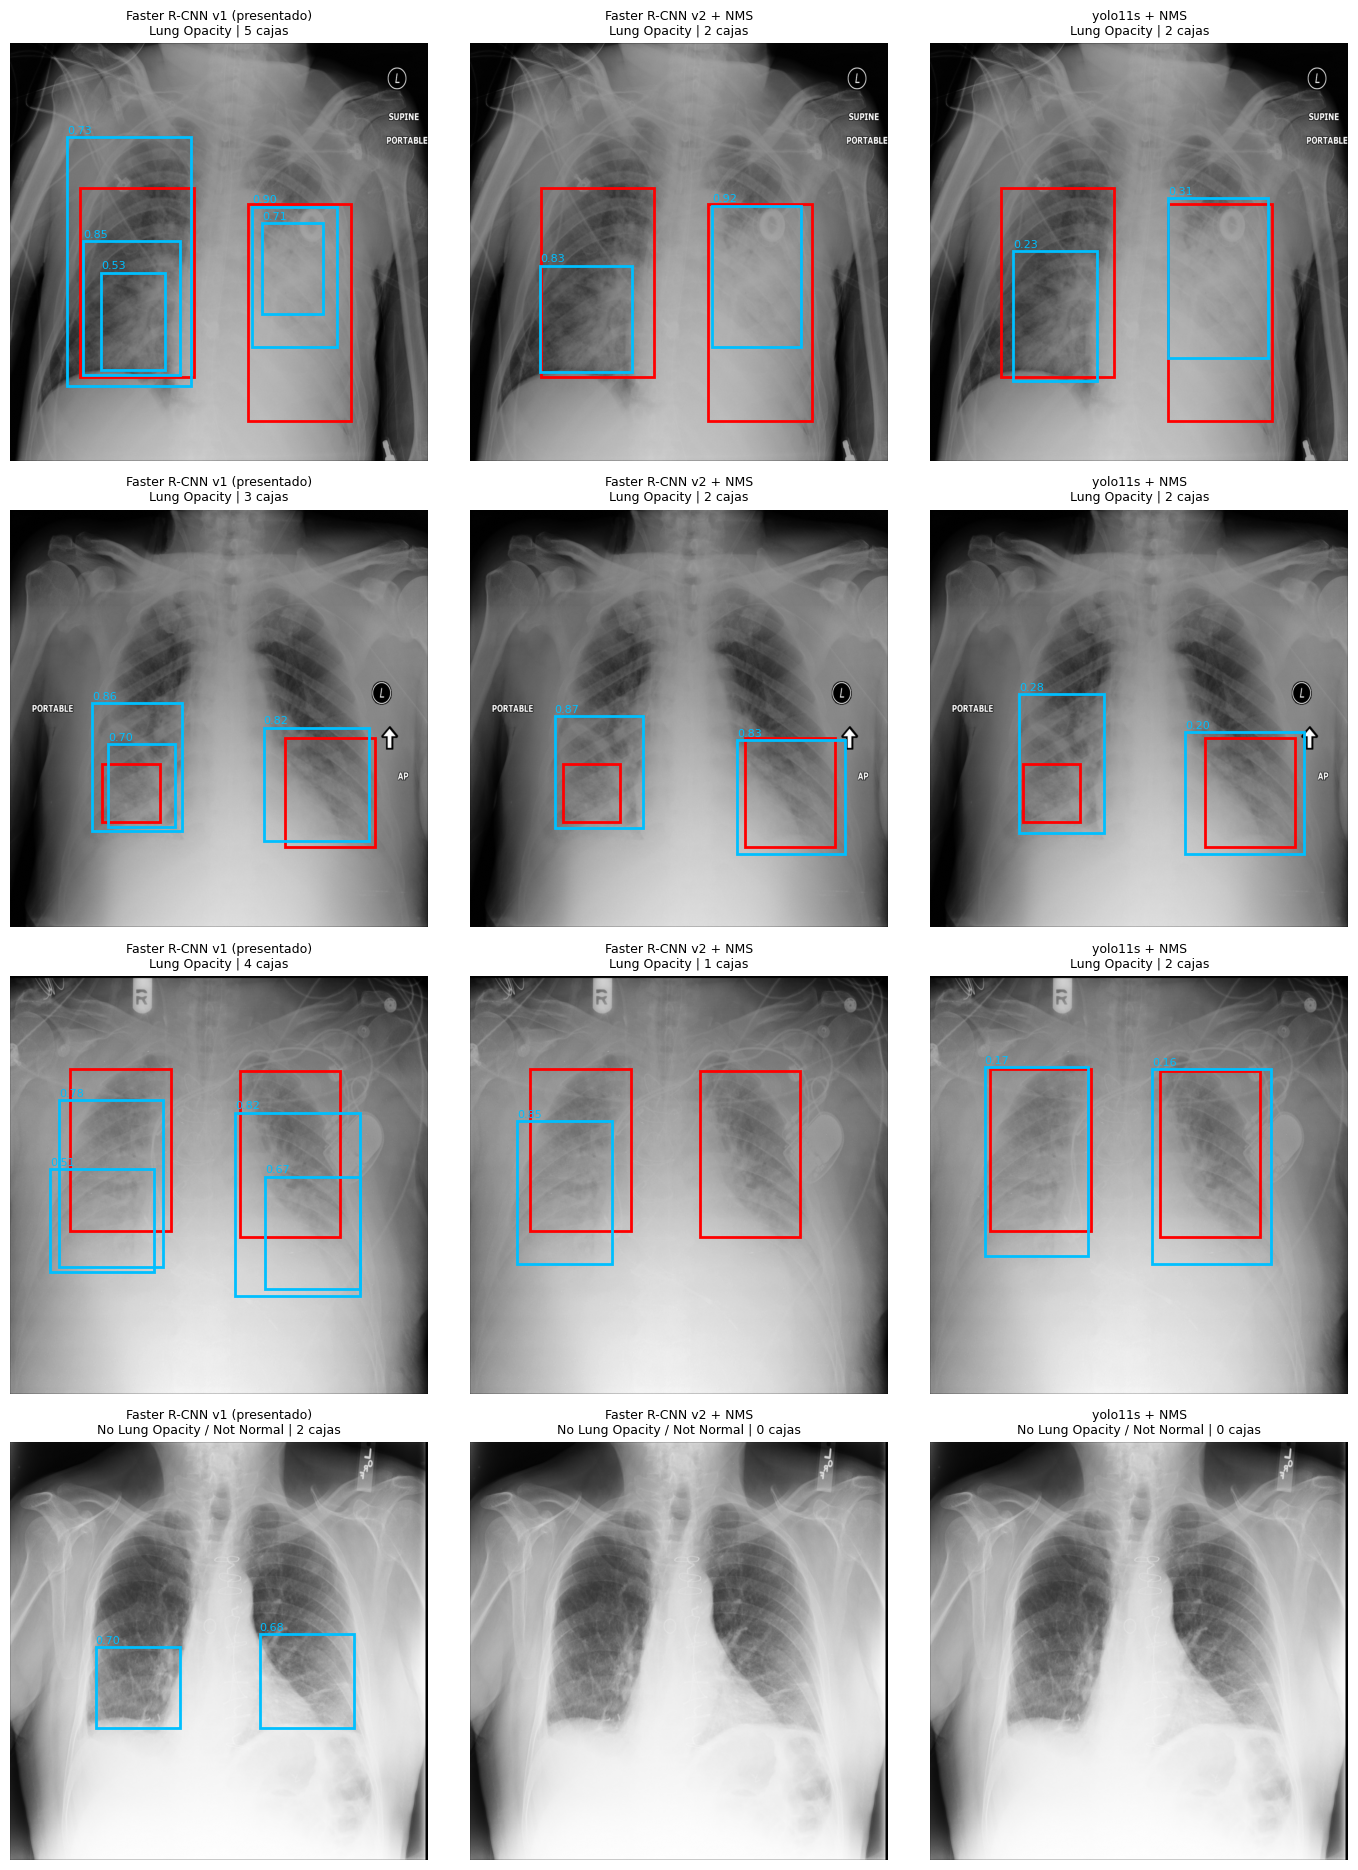

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for a, (nombre, g) in zip(ax, [("Faster R-CNN v1", grid_frcnn1), ("Faster R-CNN v2", grid_frcnn2), (YOLO_ELEGIDO, grid_yolo)]):
    b = g.loc[g.groupby("iou_nms")["f1_cajas"].idxmax()].sort_values("iou_nms")
    for col, et in [("f1_cajas", "F1"), ("precision_cajas", "Precisión"), ("recall_cajas", "Recall")]:
        a.plot(b["iou_nms"], b[col], marker="o", label=et)
    a.set_title(f"{nombre}: validación según el IoU del NMS"); a.set_xlabel("IoU del NMS (más bajo = NMS más estricto)"); a.legend()
plt.tight_layout(); guardar_fig("09_efecto_nms"); plt.show()

n_pres = n_pred_mod["Faster R-CNN v1 (presentado)"]
filas_ej = elegir(pos & (n_pres >= 3), 3) + elegir(neg & (n_pres > 0), 1)
cols = ["Faster R-CNN v1 (presentado)", "Faster R-CNN v2 + NMS", f"{YOLO_ELEGIDO} + NMS"]
fig, axes = plt.subplots(len(filas_ej), len(cols), figsize=(14, 4.7 * len(filas_ej)), squeeze=False)
for f_, i in enumerate(filas_ej):
    for c_, nombre in enumerate(cols):
        ax = axes[f_, c_]; b, s = finales[nombre][i]
        mostrar(pids_test[i], ax, f"{nombre}\n{CLASE[pids_test[i]]} | {len(b)} cajas")
        for (x1, y1, x2, y2), sc in zip(b.tolist(), s.tolist()):
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="deepskyblue", linewidth=2))
            ax.text(x1, y1 - 8, f"{sc:.2f}", color="deepskyblue", fontsize=8)
plt.tight_layout(); guardar_fig("10_ejemplos_nms"); plt.show()

- Arriba: cómo cambian F1, precisión y recall por caja en validación al hacer el NMS más estricto (IoU más bajo), para los tres modelos.
- Abajo: las mismas imágenes de test con las cajas finales del Faster R-CNN v1 presentado, el v2 con NMS y YOLO con NMS (rojo: anotación, azul: predicción). Las tres primeras son imágenes con opacidad donde el modelo presentado ponía 3 o más cajas; la última no tiene opacidad.

| Métrica (test) | Faster R-CNN v1 (presentado) | Faster R-CNN v1 + NMS | Faster R-CNN v2 (mismo post-proceso) | Faster R-CNN v2 + NMS | yolo11s (por defecto) | yolo11s + NMS |
|---|---|---|---|---|---|---|
| mAP@0.5 | 0.381 | 0.381 | 0.402 | 0.402 | 0.355 | 0.364 |
| mAP@[0.5:0.95] | 0.117 | 0.117 | 0.134 | 0.134 | 0.141 | 0.128 |
| Recall por caja (IoU ≥ 0.5) | 0.665 | 0.530 | 0.646 | 0.382 | 0.280 | 0.525 |
| Precisión por caja (IoU ≥ 0.5) | 0.226 | 0.358 | 0.271 | 0.509 | 0.527 | 0.363 |
| F1 por caja (IoU ≥ 0.5) | 0.338 | 0.428 | 0.382 | 0.437 | 0.365 | 0.430 |
| Imágenes con opacidad con ≥ 1 caja bien ubicada | 0.735 | 0.597 | 0.720 | 0.461 | 0.319 | 0.598 |
| Imágenes sin opacidad con alguna caja (falsa alarma) | 0.389 | 0.201 | 0.298 | 0.076 | 0.044 | 0.206 |
| Cajas predichas por imagen con opacidad | 2.289 | 1.362 | 2.066 | 0.868 | 0.634 | 1.340 |
| IoU medio de las parejas aceptadas | 0.668 | 0.671 | 0.689 | 0.690 | 0.720 | 0.706 |
| Cascada: imágenes con opacidad localizadas | 0.651 | 0.562 | 0.645 | 0.441 | 0.312 | 0.551 |
| Cascada: imágenes sin opacidad con caja | 0.207 | 0.153 | 0.193 | 0.068 | 0.043 | 0.163 |
| ms por imagen (aprox.) | 92.026 | 92.026 | 92.087 | 92.087 | 24.350 | 24.350 |
| Parámetros (millones) | 43.256 | 43.256 | 43.256 | 43.256 | 9.428 | 9.428 |


,F1 por caja,IC 95 % inferior,IC 95 % superior
Faster R-CNN v1 (presentado),0.338,0.319,0.356
Faster R-CNN v1 + NMS,0.428,0.403,0.451
Faster R-CNN v2 (mismo post-proceso),0.382,0.363,0.403
Faster R-CNN v2 + NMS,0.437,0.408,0.466
yolo11s (por defecto),0.365,0.335,0.396
yolo11s + NMS,0.430,0.403,0.455


- Mejor mAP@0.5 en test: **Faster R-CNN v2 (mismo post-proceso)** (0.402). Mejor F1 por caja: **Faster R-CNN v2 + NMS** (0.437).
- Mejor contra el segundo en F1: Faster R-CNN v2 + NMS − yolo11s + NMS: +0.007 en F1 por caja, IC 95 % [-0.016, +0.031] → diferencia NO distinguible del azar.
- Efecto de las mejoras de entrenamiento (mismo post-proceso): Faster R-CNN v2 (mismo post-proceso) − Faster R-CNN v1 (presentado): +0.045 en F1 por caja, IC 95 % [+0.033, +0.057] → diferencia distinguible del azar.
- Efecto del NMS elegido en Faster R-CNN v2: Faster R-CNN v2 + NMS − Faster R-CNN v2 (mismo post-proceso): +0.054 en F1 por caja, IC 95 % [+0.031, +0.078] → diferencia distinguible del azar.
- Faster R-CNN v2 + NMS contra yolo11s + NMS: Faster R-CNN v2 + NMS − yolo11s + NMS: +0.007 en F1 por caja, IC 95 % [-0.016, +0.031] → diferencia NO distinguible del azar.
- yolo11s: 9.4 M parámetros y 24 ms por imagen, frente a 43.3 M y 92 ms del Faster R-CNN.
- Como referencia, el clasificador ResNet-50 de la sección 4 tiene AUC 0.872; usando el score máximo de cada detector como clasificador: Faster R-CNN v1 (presentado) 0.8724, Faster R-CNN v2 (mismo post-proceso) 0.8907, yolo11s (por defecto) 0.8878.

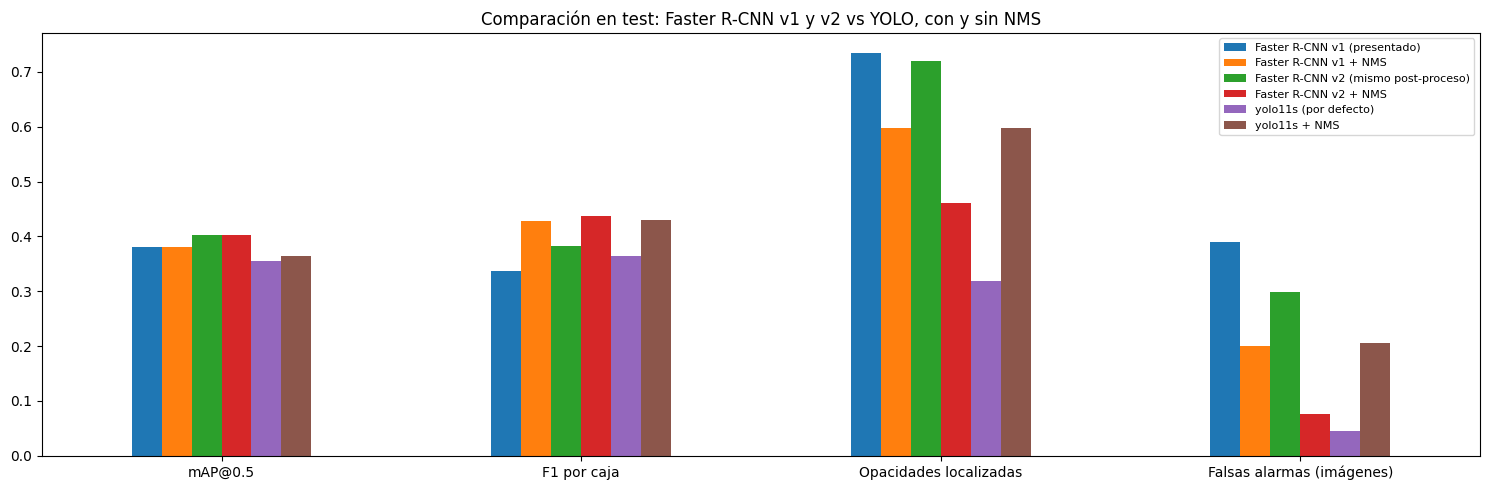

Resultados de la sección 7 guardados en: /content/drive/MyDrive/proyecto_neumonia/v3/resultados


In [ ]:
claves = ["mAP@0.5", "mAP", "recall_cajas", "precision_cajas", "f1_cajas", "imagenes_con_opacidad_localizadas",
          "imagenes_sin_opacidad_con_caja", "cajas_por_imagen_con_opacidad", "iou_medio_emparejadas", "cascada_localizadas",
          "cascada_falsas_alarmas", "ms_por_imagen", "parametros_M"]
enc = "| Métrica (test) | " + " | ".join(MODELOS) + " |\n|---|" + "---|" * len(MODELOS) + "\n"
cuerpo = "".join(f"| {NOMBRES_COMP[k]} | " + " | ".join(f"{comparacion[n][k]:.3f}" for n in MODELOS) + " |\n" for k in claves)
display(Markdown(enc + cuerpo))

# Intervalos de confianza (bootstrap sobre imágenes) para saber si las diferencias de F1 son reales
f1b = {n: f1_boot(cnt_mod[n]) for n in MODELOS}
ic = pd.DataFrame({n: {"F1 por caja": comparacion[n]["f1_cajas"], "IC 95 % inferior": np.percentile(f1b[n], 2.5),
                       "IC 95 % superior": np.percentile(f1b[n], 97.5)} for n in MODELOS}).T
display(ic.round(3)); ic.to_csv(RES_DIR / "ic_f1_cajas.csv")
metricas["ic_f1_cajas"] = ic.reset_index().to_dict(orient="records")

def comparar(a, b):
    d = f1b[a] - f1b[b]; lo, hi = np.percentile(d, [2.5, 97.5])
    veredicto = "diferencia distinguible del azar" if lo > 0 or hi < 0 else "diferencia NO distinguible del azar"
    return f"{a} − {b}: {np.mean(d):+.3f} en F1 por caja, IC 95 % [{lo:+.3f}, {hi:+.3f}] → {veredicto}"

orden = sorted(MODELOS, key=lambda n: comparacion[n]["f1_cajas"], reverse=True)
mejor_map_n = max(MODELOS, key=lambda n: comparacion[n]["mAP@0.5"])
lineas = [f"- Mejor mAP@0.5 en test: **{mejor_map_n}** ({comparacion[mejor_map_n]['mAP@0.5']:.3f}). "
          f"Mejor F1 por caja: **{orden[0]}** ({comparacion[orden[0]]['f1_cajas']:.3f}).",
          f"- Mejor contra el segundo en F1: {comparar(orden[0], orden[1])}.",
          f"- Efecto de las mejoras de entrenamiento (mismo post-proceso): {comparar('Faster R-CNN v2 (mismo post-proceso)', 'Faster R-CNN v1 (presentado)')}.",
          f"- Efecto del NMS elegido en Faster R-CNN v2: {comparar('Faster R-CNN v2 + NMS', 'Faster R-CNN v2 (mismo post-proceso)')}.",
          f"- Faster R-CNN v2 + NMS contra {YOLO_ELEGIDO} + NMS: {comparar('Faster R-CNN v2 + NMS', f'{YOLO_ELEGIDO} + NMS')}.",
          f"- {YOLO_ELEGIDO}: {params_yolo:.1f} M parámetros y {ms_yolo:.0f} ms por imagen, frente a {params_frcnn2:.1f} M y {ms_frcnn2:.0f} ms del Faster R-CNN.",
          f"- Como referencia, el clasificador ResNet-50 de la sección 4 tiene AUC {metricas['clasificacion']['auc']:.3f}; "
          f"usando el score máximo de cada detector como clasificador: " +
          ", ".join(f"{n} {comparacion[n]['auc_score_max']:.4f}" for n in (list(MODELOS)[0], list(MODELOS)[2], list(MODELOS)[4])) + "."]
display(Markdown("\n".join(lineas)))

cortas = {"mAP@0.5": "mAP@0.5", "f1_cajas": "F1 por caja", "imagenes_con_opacidad_localizadas": "Opacidades localizadas",
          "imagenes_sin_opacidad_con_caja": "Falsas alarmas (imágenes)"}
ax = tabla_comp.loc[list(cortas)].astype(float).rename(index=cortas).plot.bar(figsize=(15, 5), rot=0,
    title="Comparación en test: Faster R-CNN v1 y v2 vs YOLO, con y sin NMS")
ax.legend(fontsize=8)
plt.tight_layout(); guardar_fig("11_comparacion_final"); plt.show()

with open(RES_DIR / "metricas.json", "w") as f_:
    json.dump(metricas, f_, indent=2, ensure_ascii=False, default=str)
with open(RES_DIR / "config.json", "w") as f_:
    json.dump(config, f_, indent=2, ensure_ascii=False, default=str)
print("Resultados de la sección 7 guardados en:", RES_DIR)

- Tabla y gráfica finales de la comparación en test, con intervalos de confianza del F1 por caja (bootstrap sobre imágenes) y la comparación entre pares de modelos; todo queda guardado en Drive junto con los resultados anteriores.
- Las frases de lectura se generan con los números de esta corrida: dicen qué modelo localiza mejor, cuánto cambian las mejoras de entrenamiento y el NMS, y si cada diferencia es distinguible del azar.